# Size-Dependent Oxidation Behavior of B Nanoparticles: Analysis & Extrapolation

## B 나노입자의 크기 의존적 산화 거동 분석 및 대형 입자 외삽

**시스템 구성:**
- **Case 1**: B core + B₂O₃ shell (10 Å) + O₂ gas — 순수 산화물 쉘
- **Case 2**: B core + H₃BO₃ interlayer (5 Å) + B₂O₃ shell (10 Å) + O₂ gas — 수산화물 보조
- **B_only**: Pure B + O₂ (10nm only, control)

**입자 크기:** 6.8 nm, 10.0 nm, 15.0 nm

**핵심 질문:** H₃BO₃ 중간층이 완전 연소를 촉진하는 이유는? 더 큰 입자(50nm+)로 외삽 가능한가?

---

## 1. Setup & Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
from scipy.stats import linregress
from scipy.ndimage import uniform_filter1d
import re
import os
import warnings
warnings.filterwarnings('ignore')

# ─── Publication-quality plot settings ───
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'sans-serif',
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.linewidth': 1.2,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
})

# ─── Color scheme ───
COLOR_CASE1 = '#2166ac'  # Blue
COLOR_CASE2 = '#d6604d'  # Red
COLOR_BONLY = '#4daf4a'  # Green (control)
COLORS = {'case1': COLOR_CASE1, 'case2': COLOR_CASE2, 'B_only': COLOR_BONLY}

# Marker styles for sizes
MARKERS = {'6.8nm': 'o', '10.0nm': 's', '15.0nm': '^'}
MARKER_SIZES = {'6.8nm': 6, '10.0nm': 7, '15.0nm': 8}

# ─── Output directory for figures ───
FIG_DIR = '/mnt/dsk1/ljhlab/lammps/lammps_reaxff_B_nano/figures_extrapolation'
os.makedirs(FIG_DIR, exist_ok=True)

print("Setup complete. Figure output directory:", FIG_DIR)

Setup complete. Figure output directory: /mnt/dsk1/ljhlab/lammps/lammps_reaxff_B_nano/figures_extrapolation


In [2]:
# ─── File paths and system configuration ───
BASE = '/mnt/dsk1/ljhlab/lammps/lammps_reaxff_B_nano'
BASE_68 = os.path.join(BASE, 'result_6.8nm', 'lammps_reaxff')

# SIZE_CONFIG: diameter_nm, approximate B core radius (Å), box_length (Å)
SIZE_CONFIG = {
    '6.8nm':  {'d_nm': 6.8,  'R_core_approx': 33.9, 'box_L': 182.8823},
    '10.0nm': {'d_nm': 10.0, 'R_core_approx': 49.0, 'box_L': 208.3381},
    '15.0nm': {'d_nm': 15.0, 'R_core_approx': 74.0, 'box_L': 255.0071},
}

# Trajectory and species file paths
# key = (size_label, case_label)
FILE_PATHS = {
    ('6.8nm', 'case1'): {
        'traj': os.path.join(BASE_68, 'case1_6.8nm_prod.lammpstrj'),
        'species': os.path.join(BASE_68, 'case1_6.8nm_species.txt'),
        'data': os.path.join(BASE_68, 'case1_6.8nm_B_B2O3.data'),
    },
    ('6.8nm', 'case2'): {
        'traj': os.path.join(BASE_68, 'case2_6.8nm_prod.lammpstrj'),
        'species': os.path.join(BASE_68, 'case2_6.8nm_species.txt'),
        'data': os.path.join(BASE_68, 'case2_6.8nm_B_H3BO3_B2O3.data'),
    },
    ('10.0nm', 'case1'): {
        'traj': os.path.join(BASE, 'case1_10.0nm_prod.lammpstrj'),
        'species': os.path.join(BASE, 'case1_10.0nm_species.txt'),
    },
    ('10.0nm', 'case2'): {
        'traj': os.path.join(BASE, 'case2_10.0nm_prod_r.lammpstrj'),   # restart trajectory
        'species': os.path.join(BASE, 'case2_10.0nm_species_r.txt'),    # restart species
    },
    ('10.0nm', 'B_only'): {
        'traj': os.path.join(BASE, 'case_B_only_prod.lammpstrj'),
    },
    ('15.0nm', 'case1'): {
        'traj': os.path.join(BASE, 'case1_15.0nm_prod.lammpstrj'),
        'species': os.path.join(BASE, 'case1_15.0nm_species.txt'),
    },
    ('15.0nm', 'case2'): {
        'traj': os.path.join(BASE, 'case2_15.0nm_prod.lammpstrj'),    # partial ~408 frames
        'species': os.path.join(BASE, 'case2_15.0nm_species.txt'),
    },
}

# Simulation parameters
DT_FS = 0.25           # timestep (fs)
DUMP_EVERY = 400       # dump frequency (steps)
DT_FRAME_PS = DT_FS * DUMP_EVERY / 1000.0  # 0.1 ps per frame

# Atom types
TYPE_H, TYPE_B, TYPE_O = 1, 2, 3

# Verify file existence
print("File availability check:")
for key, paths in FILE_PATHS.items():
    traj_ok = os.path.exists(paths['traj'])
    spec_ok = os.path.exists(paths.get('species', '')) if 'species' in paths else 'N/A'
    print(f"  {key[0]:6s} {key[1]:6s} | traj: {traj_ok}  species: {spec_ok}")

File availability check:
  6.8nm  case1  | traj: True  species: True
  6.8nm  case2  | traj: True  species: True
  10.0nm case1  | traj: True  species: True
  10.0nm case2  | traj: True  species: True
  10.0nm B_only | traj: True  species: N/A
  15.0nm case1  | traj: True  species: True
  15.0nm case2  | traj: True  species: True


In [3]:
# ─── Trajectory reader (memory-efficient, reads frame by frame) ───

def read_lammpstrj_frames(filepath, frame_indices=None, max_frames=None, verbose=True):
    """
    LAMMPS trajectory 파일을 읽어서 프레임별 원자 데이터를 반환.
    
    Parameters
    ----------
    filepath : str
    frame_indices : list or None
        특정 프레임만 읽으려면 인덱스 리스트. None이면 전부 읽음.
    max_frames : int or None
        최대 읽을 프레임 수
    verbose : bool
    
    Returns
    -------
    frames : list of dict
        각 dict: {'timestep': int, 'natoms': int, 'box': (3,2) array, 
                  'id': array, 'type': array, 'x','y','z': arrays, 'q': array}
    """
    frames = []
    frame_idx = 0
    
    with open(filepath, 'r') as f:
        while True:
            # Check if we have enough frames
            if max_frames is not None and len(frames) >= max_frames:
                break
            
            line = f.readline()
            if not line:
                break
            
            if 'ITEM: TIMESTEP' not in line:
                continue
            
            # Should we read this frame?
            should_read = (frame_indices is None) or (frame_idx in frame_indices)
            
            timestep = int(f.readline().strip())
            f.readline()  # ITEM: NUMBER OF ATOMS
            natoms = int(f.readline().strip())
            f.readline()  # ITEM: BOX BOUNDS
            box = np.zeros((3, 2))
            for dim in range(3):
                lo, hi = map(float, f.readline().split())
                box[dim] = [lo, hi]
            f.readline()  # ITEM: ATOMS header
            
            if should_read:
                ids = np.zeros(natoms, dtype=int)
                types = np.zeros(natoms, dtype=int)
                x = np.zeros(natoms)
                y = np.zeros(natoms)
                z = np.zeros(natoms)
                q = np.zeros(natoms)
                
                for i in range(natoms):
                    parts = f.readline().split()
                    ids[i] = int(parts[0])
                    types[i] = int(parts[1])
                    x[i] = float(parts[2])
                    y[i] = float(parts[3])
                    z[i] = float(parts[4])
                    q[i] = float(parts[5])
                
                frames.append({
                    'timestep': timestep,
                    'natoms': natoms,
                    'box': box,
                    'id': ids,
                    'type': types,
                    'x': x, 'y': y, 'z': z,
                    'q': q,
                })
            else:
                # Skip atom lines
                for _ in range(natoms):
                    f.readline()
            
            frame_idx += 1
    
    if verbose:
        print(f"  Read {len(frames)} frames from {os.path.basename(filepath)} (total {frame_idx} frames in file)")
    return frames


def detect_B_core_radius(frame, box_L):
    """
    첫 프레임에서 B core 반지름을 자동 검출.
    전략: 박스 중심으로부터의 B 원자 거리 분포에서 급격한 밀도 변화 지점을 찾음.
    """
    center = box_L / 2.0
    mask_B = frame['type'] == TYPE_B
    
    dx = frame['x'][mask_B] - center
    dy = frame['y'][mask_B] - center
    dz = frame['z'][mask_B] - center
    r = np.sqrt(dx**2 + dy**2 + dz**2)
    
    # Radial density histogram
    r_max = box_L / 2.0
    bins = np.linspace(0, r_max, 200)
    hist, bin_edges = np.histogram(r, bins=bins)
    r_mid = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    dr = bins[1] - bins[0]
    
    # Volume-normalized density (number density in shell)
    shell_vol = 4.0 * np.pi * r_mid**2 * dr
    shell_vol[shell_vol == 0] = 1e-10
    rho = hist / shell_vol
    
    # Smooth and find where density drops below 50% of max
    rho_smooth = uniform_filter1d(rho.astype(float), size=5)
    rho_max = rho_smooth[:len(rho_smooth)//2].max()  # max in inner half
    
    threshold = 0.3 * rho_max
    below = np.where(rho_smooth < threshold)[0]
    # Find first drop after significant density
    high_region = np.where(rho_smooth > 0.5 * rho_max)[0]
    if len(high_region) > 0 and len(below) > 0:
        first_drop = below[below > high_region[-1]]
        if len(first_drop) > 0:
            R_core = r_mid[first_drop[0]]
        else:
            R_core = r_mid[high_region[-1]]
    else:
        R_core = np.percentile(r, 90)
    
    return R_core


def read_species_file(filepath, verbose=True):
    """
    LAMMPS fix reaxff/species 출력 파일 파싱.
    각 타임스텝마다 헤더가 변하므로 줄 단위로 처리.
    
    Returns
    -------
    species_data : list of dict
        각 dict: {'timestep': int, 'n_moles': int, 'n_specs': int, 'species': {name: count}}
    """
    species_data = []
    
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    i = 0
    while i < len(lines):
        line = lines[i].strip()
        if line.startswith('#'):
            # Header line: parse species names
            parts = line.split()
            # parts[0] = '#', parts[1] = 'Timestep', parts[2] = 'No_Moles', parts[3] = 'No_Specs', rest = species names
            species_names = parts[4:]
            i += 1
            if i < len(lines):
                data_parts = lines[i].strip().split()
                timestep = int(data_parts[0])
                n_moles = int(data_parts[1])
                n_specs = int(data_parts[2])
                counts = [int(x) for x in data_parts[3:]]
                
                species_dict = {}
                for name, count in zip(species_names, counts):
                    species_dict[name] = count
                
                species_data.append({
                    'timestep': timestep,
                    'n_moles': n_moles,
                    'n_specs': n_specs,
                    'species': species_dict,
                })
        i += 1
    
    if verbose:
        print(f"  Parsed {len(species_data)} timesteps from {os.path.basename(filepath)}")
    return species_data

print("Trajectory and species reader functions defined.")

Trajectory and species reader functions defined.


In [4]:
# ─── Load all trajectory data ───
# 메모리 절약을 위해 분석에 필요한 프레임만 샘플링하여 로드
# O penetration, MSD 등을 위해 ~50 프레임 균등 샘플 + 첫/끝 프레임

def get_sample_indices(n_total, n_sample=50):
    """균등 간격으로 샘플 프레임 인덱스 생성 (첫/끝 프레임 포함)"""
    if n_total <= n_sample:
        return list(range(n_total))
    indices = np.linspace(0, n_total - 1, n_sample, dtype=int).tolist()
    if 0 not in indices:
        indices = [0] + indices
    if (n_total - 1) not in indices:
        indices.append(n_total - 1)
    return sorted(set(indices))

# 전체 프레임 수 사전 정보
FRAME_COUNTS = {
    ('6.8nm', 'case1'): 1001, ('6.8nm', 'case2'): 1001,
    ('10.0nm', 'case1'): 1001, ('10.0nm', 'case2'): 1001,
    ('10.0nm', 'B_only'): 1001,
    ('15.0nm', 'case1'): 1001, ('15.0nm', 'case2'): 1001,
}

# Store loaded data
TRAJ_DATA = {}  # (size, case) -> list of frames
CORE_RADII = {}  # (size, case) -> detected R_core

print("Loading trajectories (sampled frames)...")
print("=" * 60)

for key, paths in FILE_PATHS.items():
    size_label, case_label = key
    n_frames = FRAME_COUNTS.get(key, 1001)
    sample_idx = get_sample_indices(n_frames, n_sample=50)
    
    print(f"\n{size_label} {case_label}:")
    frames = read_lammpstrj_frames(paths['traj'], frame_indices=sample_idx, verbose=True)
    TRAJ_DATA[key] = frames
    
    # Detect B core radius from first frame (with fallback to config value)
    if len(frames) > 0:
        box_L = SIZE_CONFIG[size_label]['box_L']
        R_det = detect_B_core_radius(frames[0], box_L)
        R_approx = SIZE_CONFIG[size_label]['R_core_approx']
        
        # Sanity check: detected radius should be within 50% of expected value
        # If detection fails (e.g., wrong peak), use the config value
        if R_det < R_approx * 0.5 or R_det > R_approx * 1.5:
            print(f"  ⚠ Detection failed (R_det={R_det:.1f} Å), using config R={R_approx:.1f} Å")
            CORE_RADII[key] = R_approx
        else:
            CORE_RADII[key] = R_det
            print(f"  B core radius: detected = {R_det:.1f} Å, config = {R_approx:.1f} Å")

print("\n" + "=" * 60)
print("All trajectories loaded.")

Loading trajectories (sampled frames)...

6.8nm case1:
  Read 50 frames from case1_6.8nm_prod.lammpstrj (total 1001 frames in file)
  ⚠ Detection failed (R_det=1.6 Å), using config R=33.9 Å

6.8nm case2:
  Read 50 frames from case2_6.8nm_prod.lammpstrj (total 1001 frames in file)
  B core radius: detected = 34.2 Å, config = 33.9 Å

10.0nm case1:
  Read 50 frames from case1_10.0nm_prod.lammpstrj (total 1001 frames in file)
  B core radius: detected = 48.9 Å, config = 49.0 Å

10.0nm case2:
  Read 50 frames from case2_10.0nm_prod_r.lammpstrj (total 1001 frames in file)
  B core radius: detected = 51.0 Å, config = 49.0 Å

10.0nm B_only:
  Read 50 frames from case_B_only_prod.lammpstrj (total 1001 frames in file)
  B core radius: detected = 38.0 Å, config = 49.0 Å

15.0nm case1:
  Read 50 frames from case1_15.0nm_prod.lammpstrj (total 1001 frames in file)
  B core radius: detected = 73.4 Å, config = 74.0 Å

15.0nm case2:
  Read 50 frames from case2_15.0nm_prod.lammpstrj (total 1001 frames i

In [5]:
# ─── Load species data ───
SPECIES_DATA = {}

print("Loading species files...")
for key, paths in FILE_PATHS.items():
    if 'species' in paths and os.path.exists(paths['species']):
        size_label, case_label = key
        print(f"\n{size_label} {case_label}:")
        SPECIES_DATA[key] = read_species_file(paths['species'], verbose=True)

print(f"\nSpecies data loaded for {len(SPECIES_DATA)} cases.")

Loading species files...

6.8nm case1:
  Parsed 800 timesteps from case1_6.8nm_species.txt

6.8nm case2:
  Parsed 2000 timesteps from case2_6.8nm_species.txt

10.0nm case1:
  Parsed 2000 timesteps from case1_10.0nm_species.txt

10.0nm case2:
  Parsed 2000 timesteps from case2_10.0nm_species_r.txt

15.0nm case1:
  Parsed 2000 timesteps from case1_15.0nm_species.txt

15.0nm case2:
  Parsed 2000 timesteps from case2_15.0nm_species.txt

Species data loaded for 6 cases.


---
## 2. Size-Dependent O Penetration Analysis

B core 내부로 침투한 O 원자 수를 추적하여 산화 진행 정도를 정량화.
- **O penetration**: 초기 B core 반경 이내에 위치한 O 원자 수
- **O flux**: 표면적으로 정규화한 O 침투율 (atoms/Å²/ps)

In [6]:
# ─── Compute O penetration into B core ───

def compute_O_penetration(frames, box_L, R_core):
    """
    각 프레임에서 B core 반경 내 O 원자 수를 계산.
    
    Parameters
    ----------
    frames : list of frame dicts
    box_L : float - box length
    R_core : float - B core radius (Å), 초기 프레임 기준
    
    Returns
    -------
    times : array (ps)
    N_O_in_core : array (atom count)
    """
    center = box_L / 2.0
    times = []
    N_O_core = []
    
    for frame in frames:
        t_ps = frame['timestep'] * DT_FS / 1000.0  # convert to ps
        times.append(t_ps)
        
        mask_O = frame['type'] == TYPE_O
        dx = frame['x'][mask_O] - center
        dy = frame['y'][mask_O] - center
        dz = frame['z'][mask_O] - center
        r = np.sqrt(dx**2 + dy**2 + dz**2)
        
        N_O_core.append(np.sum(r < R_core))
    
    return np.array(times), np.array(N_O_core)


# Compute for all cases
O_PENETRATION = {}  # (size, case) -> (times, N_O_core)

print("Computing O penetration into B core...")
for key in TRAJ_DATA:
    size_label, case_label = key
    box_L = SIZE_CONFIG[size_label]['box_L']
    
    # Use case1 detected core radius as reference for both cases at same size
    # (case2 has H3BO3 interlayer so B core is slightly smaller, but we use case1 as reference)
    ref_key = (size_label, 'case1') if (size_label, 'case1') in CORE_RADII else key
    R_core = CORE_RADII.get(ref_key, SIZE_CONFIG[size_label]['R_core_approx'])
    
    times, N_O = compute_O_penetration(TRAJ_DATA[key], box_L, R_core)
    O_PENETRATION[key] = (times, N_O)
    print(f"  {size_label} {case_label}: R_core={R_core:.1f} Å, "
          f"N_O(t=0)={N_O[0]}, N_O(final)={N_O[-1]}, ΔN_O={N_O[-1]-N_O[0]}")

print("\nO penetration computed for all cases.")

Computing O penetration into B core...
  6.8nm case1: R_core=33.9 Å, N_O(t=0)=489, N_O(final)=673, ΔN_O=184
  6.8nm case2: R_core=33.9 Å, N_O(t=0)=655, N_O(final)=816, ΔN_O=161
  10.0nm case1: R_core=48.9 Å, N_O(t=0)=1453, N_O(final)=1807, ΔN_O=354
  10.0nm case2: R_core=48.9 Å, N_O(t=0)=1324, N_O(final)=1734, ΔN_O=410
  10.0nm B_only: R_core=48.9 Å, N_O(t=0)=0, N_O(final)=0, ΔN_O=0
  15.0nm case1: R_core=73.4 Å, N_O(t=0)=3729, N_O(final)=4194, ΔN_O=465
  15.0nm case2: R_core=73.4 Å, N_O(t=0)=2780, N_O(final)=3622, ΔN_O=842

O penetration computed for all cases.


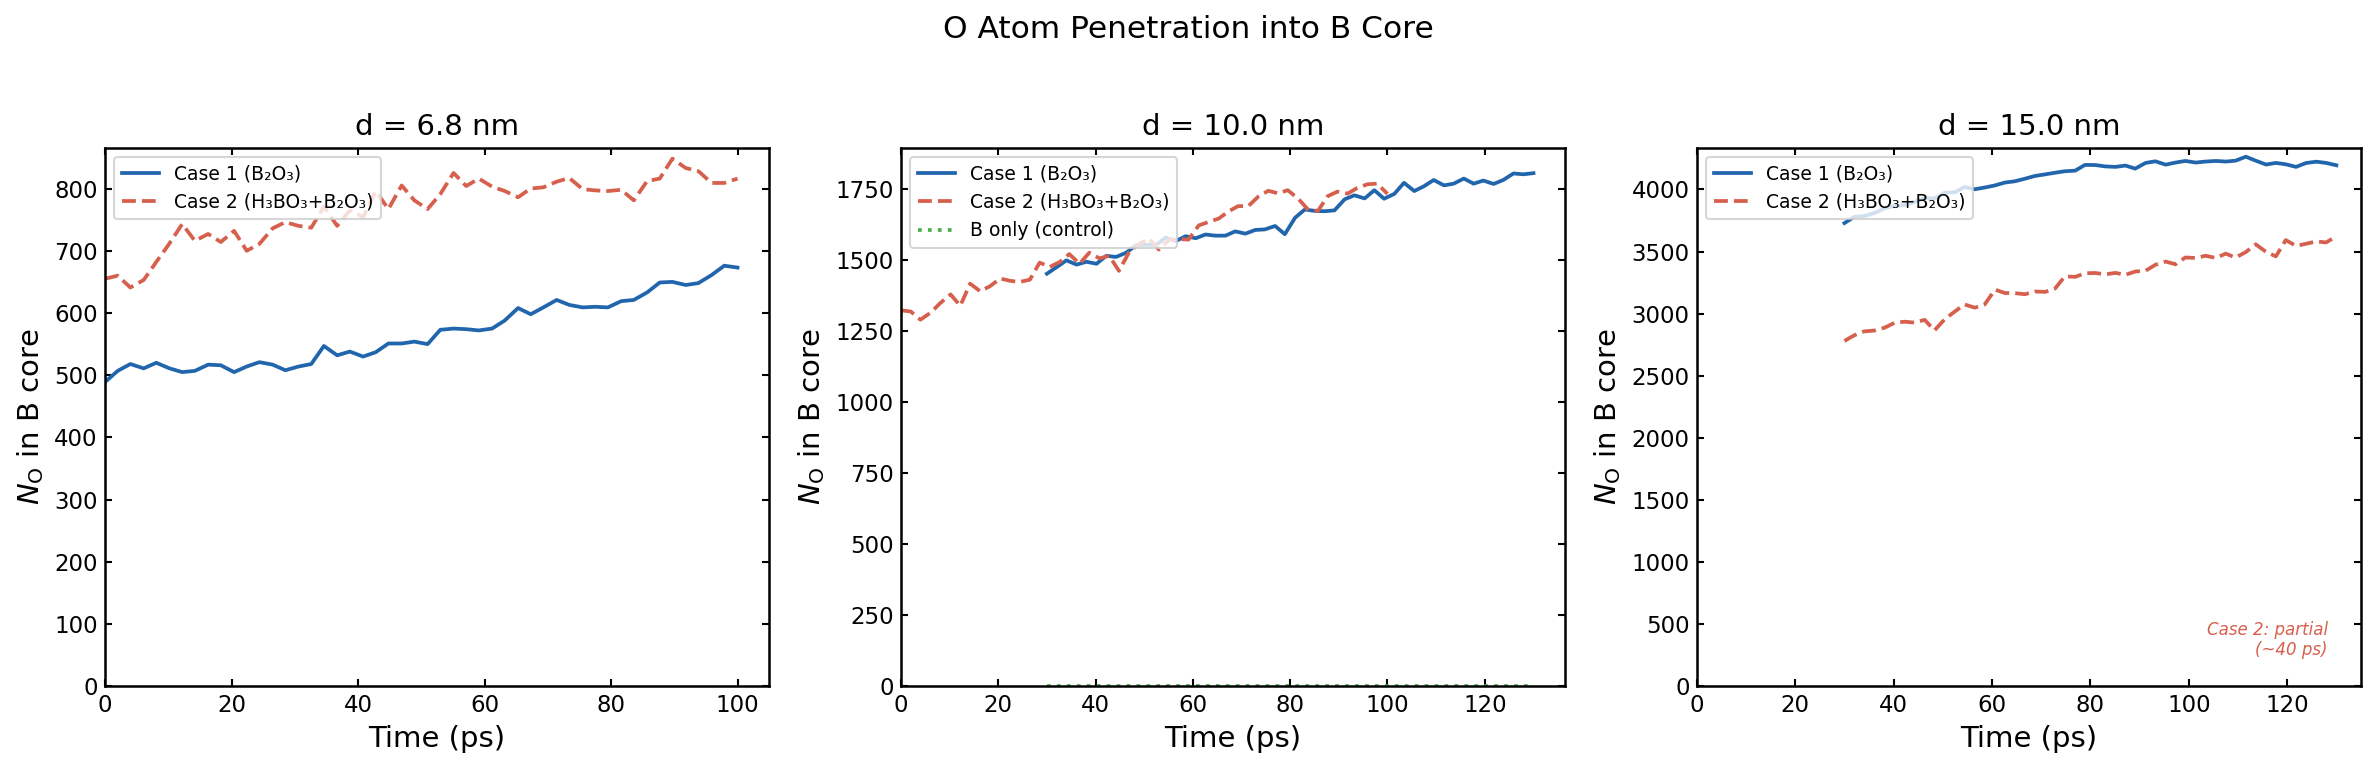

Figure saved: O_penetration_vs_time.png


In [7]:
# ─── Plot: O penetration into B core ───

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)

sizes = ['6.8nm', '10.0nm', '15.0nm']
for i, size_label in enumerate(sizes):
    ax = axes[i]
    
    for case_label in ['case1', 'case2']:
        key = (size_label, case_label)
        if key not in O_PENETRATION:
            continue
        times, N_O = O_PENETRATION[key]
        label = f"Case 1 (B₂O₃)" if case_label == 'case1' else f"Case 2 (H₃BO₃+B₂O₃)"
        color = COLORS[case_label]
        ls = '-' if case_label == 'case1' else '--'
        ax.plot(times, N_O, color=color, ls=ls, lw=1.8, label=label)
    
    # B_only control (10nm only)
    if size_label == '10.0nm' and ('10.0nm', 'B_only') in O_PENETRATION:
        times, N_O = O_PENETRATION[('10.0nm', 'B_only')]
        ax.plot(times, N_O, color=COLOR_BONLY, ls=':', lw=1.8, label='B only (control)')
    
    ax.set_xlabel('Time (ps)')
    ax.set_ylabel('$N_\\mathrm{O}$ in B core')
    ax.set_title(f'd = {SIZE_CONFIG[size_label]["d_nm"]} nm')
    ax.legend(fontsize=9, loc='upper left')
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    
    # Mark partial data for 15nm case2
    if size_label == '15.0nm':
        ax.annotate('Case 2: partial\n(~40 ps)', xy=(0.95, 0.05),
                    xycoords='axes fraction', ha='right', va='bottom',
                    fontsize=8, color=COLOR_CASE2, fontstyle='italic')

fig.suptitle('O Atom Penetration into B Core', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'O_penetration_vs_time.png'), bbox_inches='tight')
plt.show()
print("Figure saved: O_penetration_vs_time.png")

In [8]:
# ─── O penetration rate and flux analysis ───

def compute_O_flux(times, N_O, R_core):
    """
    O 침투율 계산: dN_O/dt 및 표면적 정규화 flux.
    선형 회귀로 평균 침투율 산출.
    
    Returns
    -------
    rate : float (atoms/ps) - dN_O/dt from linear fit
    rate_err : float - standard error
    flux : float (atoms/Å²/ps) - rate / surface_area
    flux_err : float
    R2 : float - R² of linear fit
    """
    surface_area = 4.0 * np.pi * R_core**2
    
    # Use data after initial transient (skip first 10% of data)
    n_skip = max(1, len(times) // 10)
    t_fit = times[n_skip:]
    N_fit = N_O[n_skip:].astype(float)
    
    if len(t_fit) < 3:
        return np.nan, np.nan, np.nan, np.nan, np.nan
    
    slope, intercept, r_value, p_value, std_err = linregress(t_fit, N_fit)
    
    rate = slope  # atoms/ps
    rate_err = std_err
    flux = rate / surface_area
    flux_err = rate_err / surface_area
    R2 = r_value**2
    
    return rate, rate_err, flux, flux_err, R2


# Compute flux for all cases
O_FLUX_RESULTS = {}

print(f"{'Size':>8s} {'Case':>8s} {'R_core(Å)':>10s} {'Rate(at/ps)':>12s} "
      f"{'Flux(at/Å²/ps)':>16s} {'R²':>8s}")
print("-" * 70)

for key in sorted(O_PENETRATION.keys()):
    size_label, case_label = key
    if case_label == 'B_only':
        continue
    
    times, N_O = O_PENETRATION[key]
    ref_key = (size_label, 'case1') if (size_label, 'case1') in CORE_RADII else key
    R_core = CORE_RADII.get(ref_key, SIZE_CONFIG[size_label]['R_core_approx'])
    
    rate, rate_err, flux, flux_err, R2 = compute_O_flux(times, N_O, R_core)
    O_FLUX_RESULTS[key] = {
        'rate': rate, 'rate_err': rate_err,
        'flux': flux, 'flux_err': flux_err,
        'R2': R2, 'R_core': R_core,
    }
    
    print(f"{size_label:>8s} {case_label:>8s} {R_core:>10.1f} "
          f"{rate:>10.2f}±{rate_err:.2f} "
          f"{flux:>14.6f}±{flux_err:.6f} {R2:>8.4f}")

    Size     Case  R_core(Å)  Rate(at/ps)   Flux(at/Å²/ps)       R²
----------------------------------------------------------------------
  10.0nm    case1       48.9       3.55±0.11       0.000118±0.000004   0.9632
  10.0nm    case2       48.9       4.65±0.17       0.000155±0.000006   0.9450
  15.0nm    case1       73.4       3.70±0.30       0.000055±0.000004   0.7756
  15.0nm    case2       73.4       7.82±0.26       0.000116±0.000004   0.9534
   6.8nm    case1       33.9       1.93±0.06       0.000134±0.000004   0.9599
   6.8nm    case2       33.9       1.26±0.11       0.000087±0.000007   0.7678


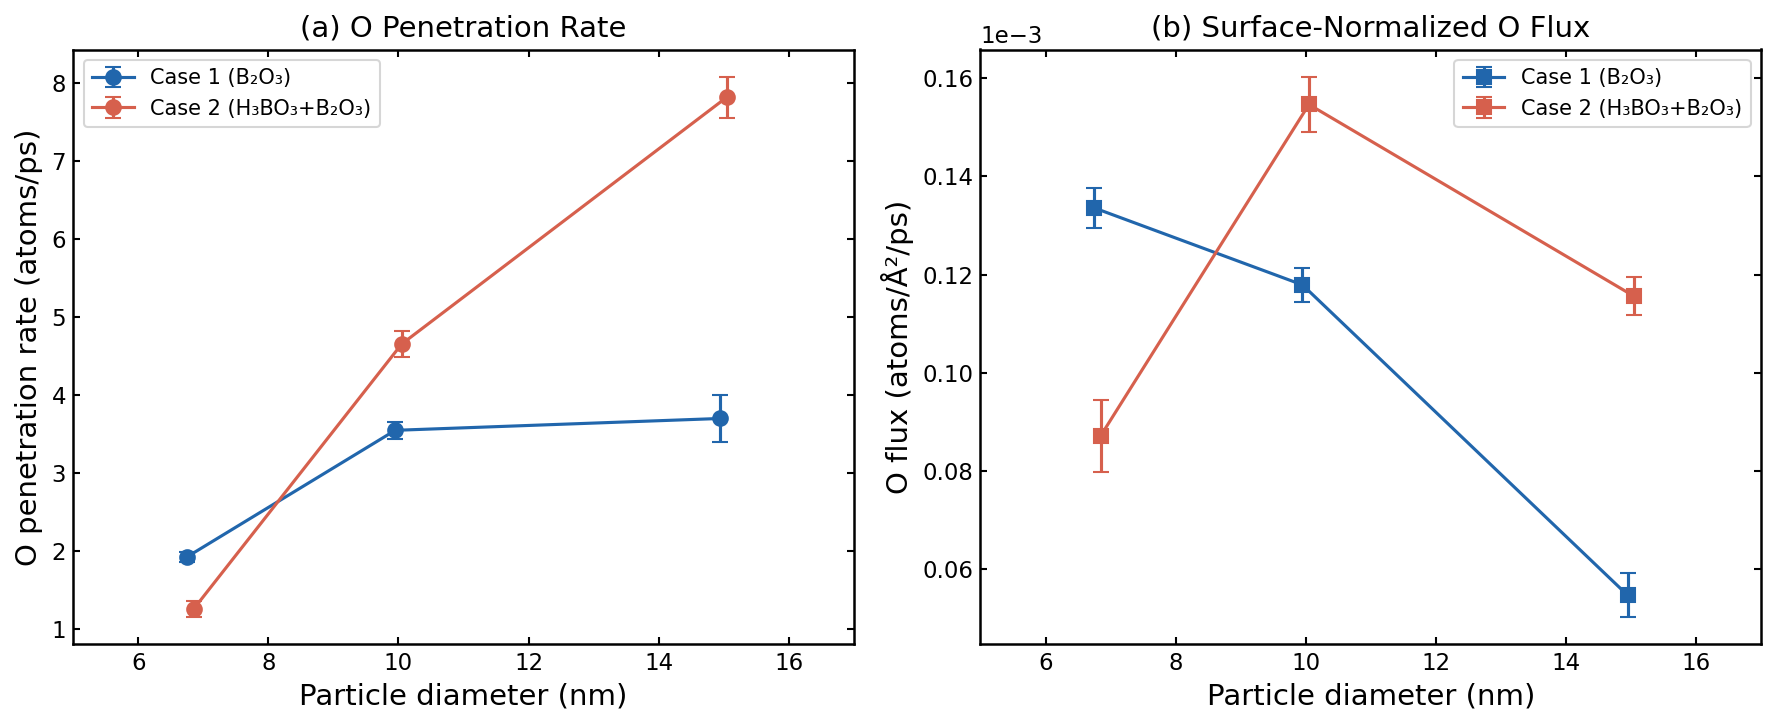

Figure saved: O_flux_vs_diameter.png


In [9]:
# ─── Plot: O flux vs particle diameter ───

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

diameters = np.array([SIZE_CONFIG[s]['d_nm'] for s in sizes])

for case_label, color, marker_offset in [('case1', COLOR_CASE1, -0.05), ('case2', COLOR_CASE2, 0.05)]:
    fluxes = []
    flux_errs = []
    rates = []
    rate_errs = []
    d_vals = []
    
    for size_label in sizes:
        key = (size_label, case_label)
        if key in O_FLUX_RESULTS:
            res = O_FLUX_RESULTS[key]
            fluxes.append(res['flux'])
            flux_errs.append(res['flux_err'])
            rates.append(res['rate'])
            rate_errs.append(res['rate_err'])
            d_vals.append(SIZE_CONFIG[size_label]['d_nm'])
    
    d_vals = np.array(d_vals)
    label = "Case 1 (B₂O₃)" if case_label == 'case1' else "Case 2 (H₃BO₃+B₂O₃)"
    
    # Rate plot
    ax1.errorbar(d_vals + marker_offset, rates, yerr=rate_errs,
                 fmt='o-', color=color, capsize=4, lw=1.5, markersize=7, label=label)
    
    # Flux plot
    ax2.errorbar(d_vals + marker_offset, fluxes, yerr=flux_errs,
                 fmt='s-', color=color, capsize=4, lw=1.5, markersize=7, label=label)

ax1.set_xlabel('Particle diameter (nm)')
ax1.set_ylabel('O penetration rate (atoms/ps)')
ax1.set_title('(a) O Penetration Rate')
ax1.legend()
ax1.set_xlim(5, 17)

ax2.set_xlabel('Particle diameter (nm)')
ax2.set_ylabel('O flux (atoms/Å²/ps)')
ax2.set_title('(b) Surface-Normalized O Flux')
ax2.legend()
ax2.set_xlim(5, 17)
ax2.ticklabel_format(axis='y', style='scientific', scilimits=(-3, -3))

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'O_flux_vs_diameter.png'), bbox_inches='tight')
plt.show()
print("Figure saved: O_flux_vs_diameter.png")

---
## 3. Size-Dependent O Diffusion Coefficient

O 원자의 평균 제곱 변위(MSD)를 계산하여 확산 계수 D를 추출.
- Einstein 관계: MSD = 6Dt (3D)
- B core 근처 O 원자만 추적 (shell/core 영역 내 O)
- **Note**: 정확한 MSD 계산을 위해서는 원자 ID로 추적해야 하지만, 
  샘플링된 프레임에서는 근사적 방법 사용 (radial MSD proxy)

In [10]:
# ─── Compute O diffusion via atom-tracking MSD ───
# 원래 방식: 모든 O 원자를 ID 기반으로 추적 (영역 제한 없음)

def compute_O_MSD_tracked(frames, box_L, R_core, shell_buffer=None):
    """
    모든 O 원자를 ID 기반으로 추적하여 MSD 계산.
    첫 프레임에 존재하는 모든 O 원자를 추적 대상으로 삼음.
    
    Parameters
    ----------
    frames : list of frame dicts (sorted by time)
    box_L : float
    R_core : float - B core radius (unused, kept for API compatibility)
    shell_buffer : ignored (kept for API compatibility)
    
    Returns
    -------
    times : array (ps), relative to first frame
    msd : array (Å²) - mean squared displacement
    n_tracked : int - 추적된 O 원자 수
    """
    # Frame 0: select ALL O atoms (no radial filter)
    f0 = frames[0]
    mask_O0 = f0['type'] == TYPE_O
    ids_O0 = f0['id'][mask_O0]
    x0 = f0['x'][mask_O0]
    y0 = f0['y'][mask_O0]
    z0 = f0['z'][mask_O0]
    
    n_tracked = len(ids_O0)
    
    if n_tracked == 0:
        return np.array([]), np.array([]), 0
    
    # Build reference positions (frame 0) — all O atoms
    id_to_idx0 = {}
    for idx_local, aid in enumerate(ids_O0):
        id_to_idx0[int(aid)] = idx_local
    
    ref_x = x0.copy()
    ref_y = y0.copy()
    ref_z = z0.copy()
    
    t0_ps = frames[0]['timestep'] * DT_FS / 1000.0
    times = []
    msd_vals = []
    
    for frame in frames:
        t_ps = frame['timestep'] * DT_FS / 1000.0 - t0_ps
        times.append(t_ps)
        
        # Find tracked atoms in this frame
        mask_O = frame['type'] == TYPE_O
        ids_frame = frame['id'][mask_O]
        x_frame = frame['x'][mask_O]
        y_frame = frame['y'][mask_O]
        z_frame = frame['z'][mask_O]
        
        sq_displacements = []
        for j, aid in enumerate(ids_frame):
            aid_int = int(aid)
            if aid_int in id_to_idx0:
                idx0 = id_to_idx0[aid_int]
                ddx = x_frame[j] - ref_x[idx0]
                ddy = y_frame[j] - ref_y[idx0]
                ddz = z_frame[j] - ref_z[idx0]
                
                # Minimum image convention
                ddx -= box_L * np.round(ddx / box_L)
                ddy -= box_L * np.round(ddy / box_L)
                ddz -= box_L * np.round(ddz / box_L)
                
                sq_displacements.append(ddx**2 + ddy**2 + ddz**2)
        
        if len(sq_displacements) > 0:
            msd_vals.append(np.mean(sq_displacements))
        else:
            msd_vals.append(np.nan)
    
    return np.array(times), np.array(msd_vals), n_tracked


# Compute MSD for all cases (excluding B_only for now)
MSD_RESULTS = {}

print("Computing O MSD (all O atoms tracked)...")
for key in TRAJ_DATA:
    size_label, case_label = key
    if case_label == 'B_only':
        continue
    
    box_L = SIZE_CONFIG[size_label]['box_L']
    ref_key = (size_label, 'case1') if (size_label, 'case1') in CORE_RADII else key
    R_core = CORE_RADII.get(ref_key, SIZE_CONFIG[size_label]['R_core_approx'])
    
    times, msd, n_tracked = compute_O_MSD_tracked(TRAJ_DATA[key], box_L, R_core)
    MSD_RESULTS[key] = {'times': times, 'msd': msd, 'n_tracked': n_tracked}
    print(f"  {size_label} {case_label}: {n_tracked} O atoms tracked")

Computing O MSD (atom-tracked)...
  6.8nm case1: 1773 O atoms tracked
  6.8nm case2: 1959 O atoms tracked
  10.0nm case1: 3818 O atoms tracked
  10.0nm case2: 3859 O atoms tracked
  15.0nm case1: 7757 O atoms tracked
  15.0nm case2: 8181 O atoms tracked


In [11]:
# ─── Extract D from MSD and plot ───

def extract_diffusion_coeff(times, msd, fit_frac=(0.2, 0.8)):
    """
    MSD의 선형 영역에서 D 추출.
    MSD = 6Dt → D = slope / 6
    
    fit_frac: (start_frac, end_frac) of total time to use for fitting
    """
    valid = ~np.isnan(msd) & (times > 0)
    t_v = times[valid]
    msd_v = msd[valid]
    
    if len(t_v) < 5:
        return np.nan, np.nan, np.nan
    
    t_max = t_v[-1]
    t_start = t_max * fit_frac[0]
    t_end = t_max * fit_frac[1]
    
    fit_mask = (t_v >= t_start) & (t_v <= t_end)
    if fit_mask.sum() < 3:
        fit_mask = np.ones(len(t_v), dtype=bool)
    
    slope, intercept, r_value, p_value, std_err = linregress(t_v[fit_mask], msd_v[fit_mask])
    
    D = slope / 6.0  # Å²/ps
    D_err = std_err / 6.0
    R2 = r_value**2
    
    return D, D_err, R2


DIFF_COEFF = {}

print(f"{'Size':>8s} {'Case':>8s} {'D (Å²/ps)':>14s} {'D (cm²/s)':>16s} {'R²':>8s}")
print("-" * 60)

for key in sorted(MSD_RESULTS.keys()):
    size_label, case_label = key
    res = MSD_RESULTS[key]
    
    D, D_err, R2 = extract_diffusion_coeff(res['times'], res['msd'])
    DIFF_COEFF[key] = {'D': D, 'D_err': D_err, 'R2': R2}
    
    # Convert: 1 Å²/ps = 1e-16 m² / 1e-12 s = 1e-4 m²/s = 1 cm²/s × 1e-4... 
    # Actually: 1 Å² = 1e-20 m², 1 ps = 1e-12 s → D in m²/s = D * 1e-20/1e-12 = D * 1e-8 m²/s
    # D in cm²/s = D * 1e-8 * 1e4 = D * 1e-4 cm²/s
    D_cgs = D * 1e-4  # cm²/s
    D_err_cgs = D_err * 1e-4
    
    print(f"{size_label:>8s} {case_label:>8s} {D:>10.4f}±{D_err:.4f} "
          f"{D_cgs:>12.4e}±{D_err_cgs:.1e} {R2:>8.4f}")

    Size     Case      D (Å²/ps)        D (cm²/s)       R²
------------------------------------------------------------
  10.0nm    case1     5.4055±0.3122   5.4055e-04±3.1e-05   0.9146
  10.0nm    case2     5.2773±0.3541   5.2773e-04±3.5e-05   0.8880
  15.0nm    case1     8.9911±0.3714   8.9911e-04±3.7e-05   0.9544
  15.0nm    case2    10.0650±0.4153   1.0065e-03±4.2e-05   0.9545
   6.8nm    case1     2.5955±0.2506   2.5955e-04±2.5e-05   0.7931
   6.8nm    case2     3.5597±0.3101   3.5597e-04±3.1e-05   0.8248


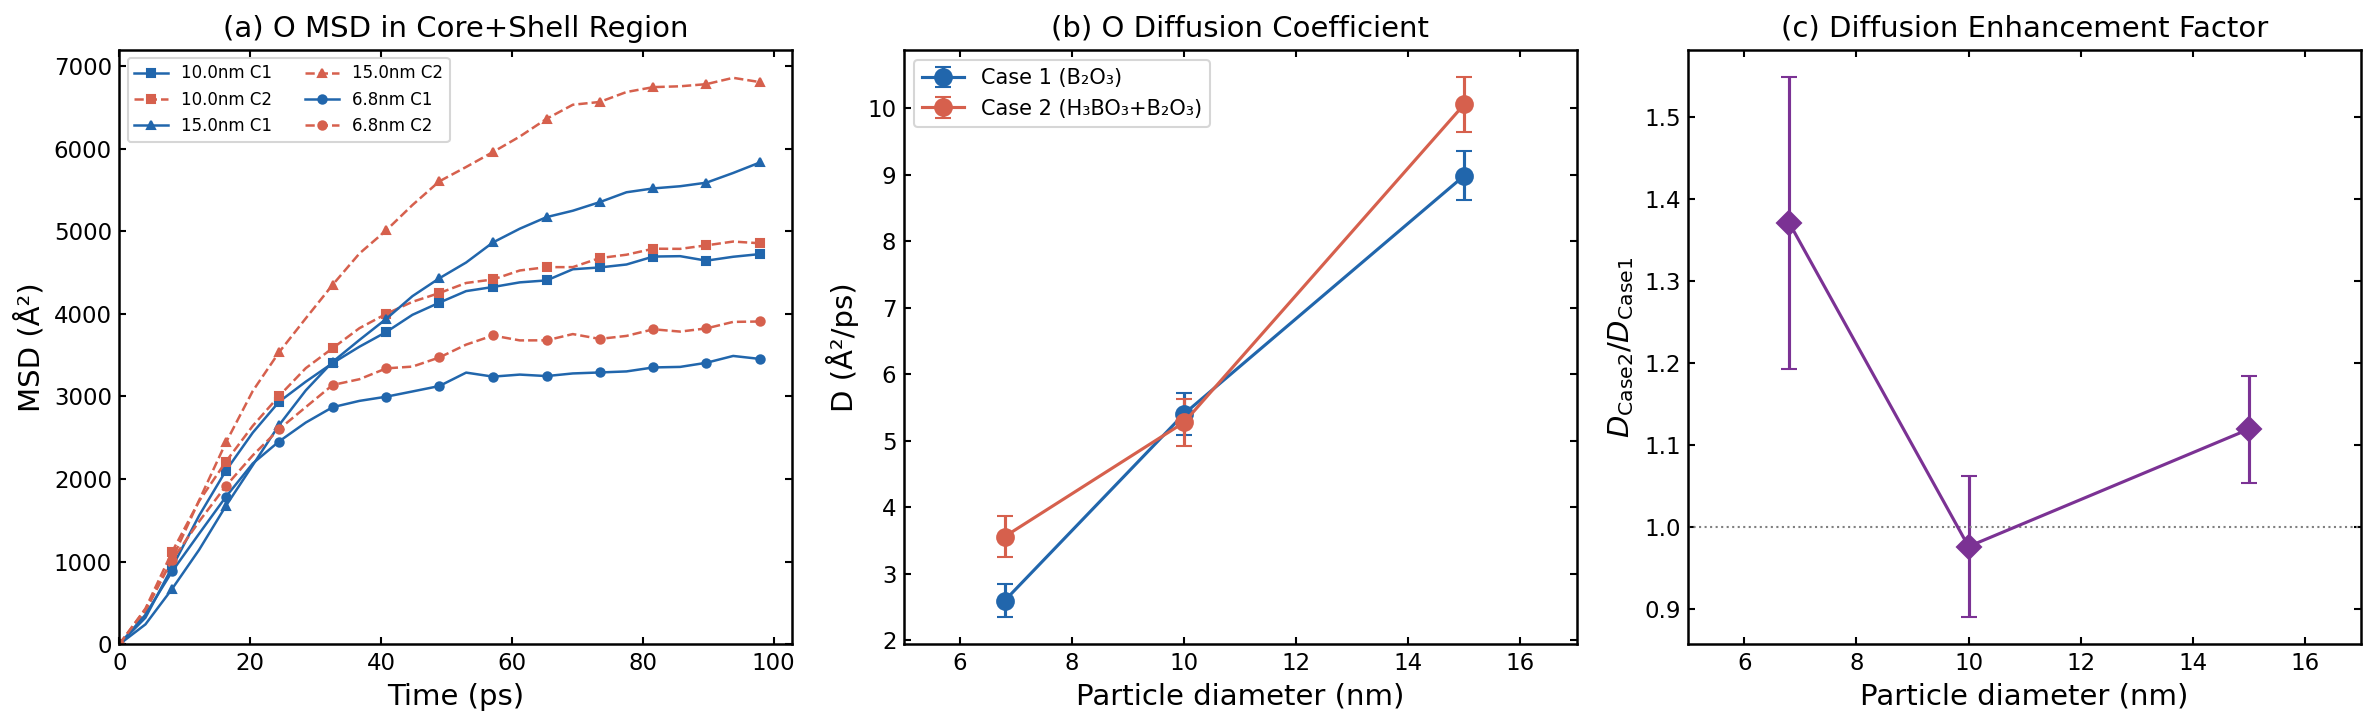

Figure saved: MSD_and_diffusion.png


In [12]:
# ─── Plot MSD and D vs size ───

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# (a) MSD vs time for each size
ax = axes[0]
for key in sorted(MSD_RESULTS.keys()):
    size_label, case_label = key
    res = MSD_RESULTS[key]
    t, msd = res['times'], res['msd']
    
    color = COLORS.get(case_label, 'gray')
    ls = '-' if case_label == 'case1' else '--'
    marker = MARKERS.get(size_label, 'o')
    label = f"{size_label} {'C1' if case_label == 'case1' else 'C2'}"
    
    # Plot every 5th point for clarity
    step = max(1, len(t) // 20)
    ax.plot(t[::step], msd[::step], color=color, ls=ls, marker=marker,
            markersize=4, lw=1.2, label=label, markevery=2)

ax.set_xlabel('Time (ps)')
ax.set_ylabel('MSD (Å²)')
ax.set_title('(a) O MSD in Core+Shell Region')
ax.legend(fontsize=8, ncol=2, loc='upper left')
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

# (b) D vs particle diameter
ax = axes[1]
for case_label, color in [('case1', COLOR_CASE1), ('case2', COLOR_CASE2)]:
    d_vals = []
    D_vals = []
    D_errs = []
    for size_label in sizes:
        key = (size_label, case_label)
        if key in DIFF_COEFF and not np.isnan(DIFF_COEFF[key]['D']):
            d_vals.append(SIZE_CONFIG[size_label]['d_nm'])
            D_vals.append(DIFF_COEFF[key]['D'])
            D_errs.append(DIFF_COEFF[key]['D_err'])
    
    label = "Case 1 (B₂O₃)" if case_label == 'case1' else "Case 2 (H₃BO₃+B₂O₃)"
    ax.errorbar(d_vals, D_vals, yerr=D_errs, fmt='o-', color=color,
                capsize=4, lw=1.5, markersize=8, label=label)

ax.set_xlabel('Particle diameter (nm)')
ax.set_ylabel('D (Å²/ps)')
ax.set_title('(b) O Diffusion Coefficient')
ax.legend()
ax.set_xlim(5, 17)

# (c) D ratio (Case2/Case1) = enhancement factor
ax = axes[2]
d_vals_ratio = []
D_ratio_vals = []
D_ratio_errs = []

for size_label in sizes:
    k1 = (size_label, 'case1')
    k2 = (size_label, 'case2')
    if k1 in DIFF_COEFF and k2 in DIFF_COEFF:
        D1 = DIFF_COEFF[k1]['D']
        D2 = DIFF_COEFF[k2]['D']
        if D1 > 0 and not np.isnan(D1) and not np.isnan(D2):
            ratio = D2 / D1
            # Error propagation: δ(D2/D1) = ratio * sqrt((δD2/D2)² + (δD1/D1)²)
            e1 = DIFF_COEFF[k1]['D_err']
            e2 = DIFF_COEFF[k2]['D_err']
            ratio_err = ratio * np.sqrt((e2/D2)**2 + (e1/D1)**2) if D2 > 0 else 0
            d_vals_ratio.append(SIZE_CONFIG[size_label]['d_nm'])
            D_ratio_vals.append(ratio)
            D_ratio_errs.append(ratio_err)

ax.errorbar(d_vals_ratio, D_ratio_vals, yerr=D_ratio_errs,
            fmt='D-', color='#7b3294', capsize=4, lw=1.5, markersize=8)
ax.axhline(y=1.0, color='gray', ls=':', lw=1)
ax.set_xlabel('Particle diameter (nm)')
ax.set_ylabel('$D_{\\mathrm{Case2}} / D_{\\mathrm{Case1}}$')
ax.set_title('(c) Diffusion Enhancement Factor')
ax.set_xlim(5, 17)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'MSD_and_diffusion.png'), bbox_inches='tight')
plt.show()
print("Figure saved: MSD_and_diffusion.png")

---
## 4. Shell Degradation Kinetics

B₂O₃ shell의 구조적 완전성을 시간에 따라 추적.
- Shell 영역: R_core ~ R_core + shell_thickness (10 Å)
- Case 2의 경우 H₃BO₃ 중간층 (R_core - 5 Å ~ R_core) 내 H 손실도 추적
- **Key metric**: Shell half-life (50% 분해 시간)

In [13]:
# ─── Shell degradation analysis ───

SHELL_THICKNESS = 10.0  # Å (B2O3 shell)
H3BO3_THICKNESS = 5.0   # Å (H3BO3 interlayer, only for case2)

def compute_shell_integrity(frames, box_L, R_core, shell_thick=10.0, h3bo3_thick=5.0, has_h3bo3=False):
    """
    Shell 영역 내 원자 수 추적으로 shell 무결성 계산.
    
    Returns
    -------
    times : array (ps)
    shell_O_frac : array - shell 내 O 원자 비율 (초기 대비)
    shell_B_frac : array - shell 내 B 원자 비율
    h_frac : array or None - H3BO3 layer 내 H 비율 (case2만)
    """
    center = box_L / 2.0
    R_shell_inner = R_core
    R_shell_outer = R_core + shell_thick
    
    if has_h3bo3:
        R_h3bo3_inner = R_core - h3bo3_thick
        R_h3bo3_outer = R_core
    
    # Count atoms in shell region at t=0
    f0 = frames[0]
    
    def count_in_shell(frame, R_in, R_out, atom_type):
        mask = frame['type'] == atom_type
        dx = frame['x'][mask] - center
        dy = frame['y'][mask] - center
        dz = frame['z'][mask] - center
        r = np.sqrt(dx**2 + dy**2 + dz**2)
        return np.sum((r >= R_in) & (r < R_out))
    
    N_O_shell_0 = count_in_shell(f0, R_shell_inner, R_shell_outer, TYPE_O)
    N_B_shell_0 = count_in_shell(f0, R_shell_inner, R_shell_outer, TYPE_B)
    
    if has_h3bo3:
        N_H_h3bo3_0 = count_in_shell(f0, R_h3bo3_inner, R_h3bo3_outer, TYPE_H)
    
    times = []
    shell_O_frac = []
    shell_B_frac = []
    h_frac = [] if has_h3bo3 else None
    
    for frame in frames:
        t_ps = frame['timestep'] * DT_FS / 1000.0
        times.append(t_ps)
        
        N_O = count_in_shell(frame, R_shell_inner, R_shell_outer, TYPE_O)
        N_B = count_in_shell(frame, R_shell_inner, R_shell_outer, TYPE_B)
        
        shell_O_frac.append(N_O / max(N_O_shell_0, 1))
        shell_B_frac.append(N_B / max(N_B_shell_0, 1))
        
        if has_h3bo3:
            N_H = count_in_shell(frame, R_h3bo3_inner, R_h3bo3_outer, TYPE_H)
            h_frac.append(N_H / max(N_H_h3bo3_0, 1))
    
    return (np.array(times), np.array(shell_O_frac), np.array(shell_B_frac),
            np.array(h_frac) if has_h3bo3 else None,
            {'N_O_0': N_O_shell_0, 'N_B_0': N_B_shell_0, 
             'N_H_0': N_H_h3bo3_0 if has_h3bo3 else 0})


# Compute shell integrity for all cases
SHELL_DATA = {}

print("Computing shell degradation...")
for key in TRAJ_DATA:
    size_label, case_label = key
    if case_label == 'B_only':
        continue
    
    box_L = SIZE_CONFIG[size_label]['box_L']
    ref_key = (size_label, 'case1') if (size_label, 'case1') in CORE_RADII else key
    R_core = CORE_RADII.get(ref_key, SIZE_CONFIG[size_label]['R_core_approx'])
    
    has_h3bo3 = (case_label == 'case2')
    
    times, O_frac, B_frac, H_frac, counts = compute_shell_integrity(
        TRAJ_DATA[key], box_L, R_core,
        shell_thick=SHELL_THICKNESS, h3bo3_thick=H3BO3_THICKNESS,
        has_h3bo3=has_h3bo3
    )
    
    SHELL_DATA[key] = {
        'times': times, 'O_frac': O_frac, 'B_frac': B_frac,
        'H_frac': H_frac, 'counts_0': counts,
    }
    
    h_info = f", N_H_0={counts['N_H_0']}" if has_h3bo3 else ""
    print(f"  {size_label} {case_label}: N_O_shell_0={counts['N_O_0']}, "
          f"N_B_shell_0={counts['N_B_0']}{h_info}")

Computing shell degradation...
  6.8nm case1: N_O_shell_0=960, N_B_shell_0=2121
  6.8nm case2: N_O_shell_0=763, N_B_shell_0=4413, N_H_0=5
  10.0nm case1: N_O_shell_0=1618, N_B_shell_0=1354
  10.0nm case2: N_O_shell_0=1696, N_B_shell_0=6072, N_H_0=38
  15.0nm case1: N_O_shell_0=2799, N_B_shell_0=1692
  15.0nm case2: N_O_shell_0=3628, N_B_shell_0=15903, N_H_0=115


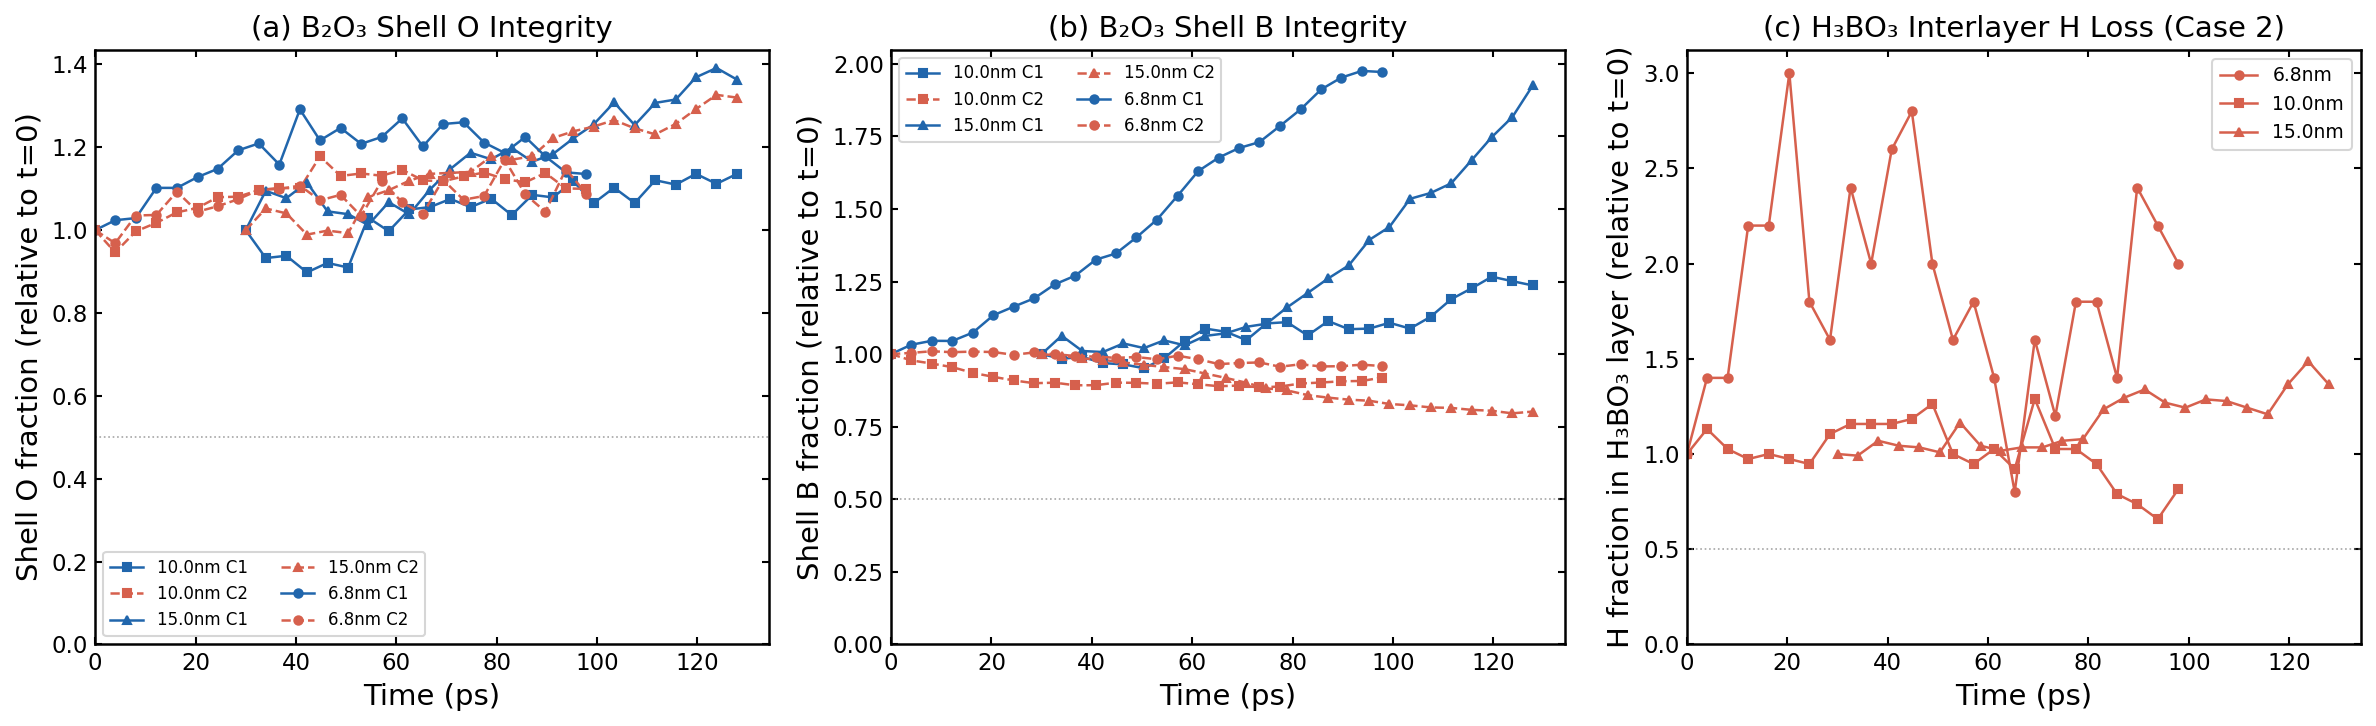

Figure saved: shell_degradation.png


In [14]:
# ─── Plot shell degradation ───

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# (a) Shell O fraction vs time
ax = axes[0]
for key in sorted(SHELL_DATA.keys()):
    size_label, case_label = key
    sd = SHELL_DATA[key]
    color = COLORS[case_label]
    ls = '-' if case_label == 'case1' else '--'
    marker = MARKERS[size_label]
    label = f"{size_label} {'C1' if case_label == 'case1' else 'C2'}"
    
    step = max(1, len(sd['times']) // 25)
    ax.plot(sd['times'][::step], sd['O_frac'][::step], color=color, ls=ls,
            marker=marker, markersize=4, lw=1.2, label=label)

ax.axhline(y=0.5, color='gray', ls=':', lw=0.8, alpha=0.7)
ax.set_xlabel('Time (ps)')
ax.set_ylabel('Shell O fraction (relative to t=0)')
ax.set_title('(a) B₂O₃ Shell O Integrity')
ax.legend(fontsize=8, ncol=2, loc='best')
ax.set_xlim(left=0)
ax.set_ylim(0, None)

# (b) Shell B fraction vs time
ax = axes[1]
for key in sorted(SHELL_DATA.keys()):
    size_label, case_label = key
    sd = SHELL_DATA[key]
    color = COLORS[case_label]
    ls = '-' if case_label == 'case1' else '--'
    marker = MARKERS[size_label]
    label = f"{size_label} {'C1' if case_label == 'case1' else 'C2'}"
    
    step = max(1, len(sd['times']) // 25)
    ax.plot(sd['times'][::step], sd['B_frac'][::step], color=color, ls=ls,
            marker=marker, markersize=4, lw=1.2, label=label)

ax.axhline(y=0.5, color='gray', ls=':', lw=0.8, alpha=0.7)
ax.set_xlabel('Time (ps)')
ax.set_ylabel('Shell B fraction (relative to t=0)')
ax.set_title('(b) B₂O₃ Shell B Integrity')
ax.legend(fontsize=8, ncol=2, loc='best')
ax.set_xlim(left=0)
ax.set_ylim(0, None)

# (c) H loss from H3BO3 layer (case2 only)
ax = axes[2]
for size_label in sizes:
    key = (size_label, 'case2')
    if key in SHELL_DATA and SHELL_DATA[key]['H_frac'] is not None:
        sd = SHELL_DATA[key]
        marker = MARKERS[size_label]
        
        step = max(1, len(sd['times']) // 25)
        ax.plot(sd['times'][::step], sd['H_frac'][::step], color=COLOR_CASE2,
                marker=marker, markersize=4, lw=1.2, label=f"{size_label}")

ax.axhline(y=0.5, color='gray', ls=':', lw=0.8, alpha=0.7)
ax.set_xlabel('Time (ps)')
ax.set_ylabel('H fraction in H₃BO₃ layer (relative to t=0)')
ax.set_title('(c) H₃BO₃ Interlayer H Loss (Case 2)')
ax.legend(fontsize=9)
ax.set_xlim(left=0)
ax.set_ylim(0, None)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'shell_degradation.png'), bbox_inches='tight')
plt.show()
print("Figure saved: shell_degradation.png")

In [15]:
# ─── Estimate shell half-life ───

def estimate_half_life(times, frac, target=0.5):
    """
    fraction 데이터에서 half-life 추정 (target fraction에 도달하는 시간).
    선형 보간 사용.
    """
    # Find where fraction first crosses target (from above)
    for i in range(1, len(frac)):
        if frac[i] <= target and frac[i-1] > target:
            # Linear interpolation
            t_half = times[i-1] + (times[i] - times[i-1]) * (frac[i-1] - target) / (frac[i-1] - frac[i])
            return t_half
    
    # If never reaches target, estimate by exponential fit
    valid = frac > 0.1  # avoid near-zero values
    if valid.sum() > 5:
        try:
            # fit: frac = A * exp(-k*t)
            log_frac = np.log(np.clip(frac[valid], 1e-6, None))
            slope, intercept, _, _, _ = linregress(times[valid], log_frac)
            if slope < 0:
                k = -slope
                t_half = np.log(2) / k
                return t_half
        except:
            pass
    
    return np.inf  # Never reached half-life


SHELL_HALFLIFE = {}

print(f"{'Size':>8s} {'Case':>8s} {'O half-life (ps)':>18s} {'B half-life (ps)':>18s} {'H half-life (ps)':>18s}")
print("-" * 75)

for key in sorted(SHELL_DATA.keys()):
    size_label, case_label = key
    sd = SHELL_DATA[key]
    
    t_half_O = estimate_half_life(sd['times'], sd['O_frac'])
    t_half_B = estimate_half_life(sd['times'], sd['B_frac'])
    
    t_half_H = np.nan
    if sd['H_frac'] is not None and len(sd['H_frac']) > 0:
        t_half_H = estimate_half_life(sd['times'], sd['H_frac'])
    
    SHELL_HALFLIFE[key] = {'O': t_half_O, 'B': t_half_B, 'H': t_half_H}
    
    h_str = f"{t_half_H:>16.2f}" if not np.isnan(t_half_H) else f"{'N/A':>16s}"
    o_str = f"{t_half_O:>16.2f}" if not np.isinf(t_half_O) else f"{'>100':>16s}"
    b_str = f"{t_half_B:>16.2f}" if not np.isinf(t_half_B) else f"{'>100':>16s}"
    
    print(f"{size_label:>8s} {case_label:>8s} {o_str} {b_str} {h_str}")

    Size     Case   O half-life (ps)   B half-life (ps)   H half-life (ps)
---------------------------------------------------------------------------
  10.0nm    case1             >100             >100              N/A
  10.0nm    case2             >100          1099.95           173.93
  15.0nm    case1             >100             >100              N/A
  15.0nm    case2             >100           268.48              inf
   6.8nm    case1             >100             >100              N/A
   6.8nm    case2             >100          1138.94           511.53


---
## 5. Oxidation Efficiency (from Species Data)

ReaxFF species 분석으로 산화 진행도 정량화.
- O₂ 소비량 추적
- B-O 결합 종 (B₂O₃, BO, BO₂ 등) 추적  
- 산화 진행도 = 소비된 O₂ / 초기 O₂
- H₂O 생성 (Case 2에서 H₃BO₃ 분해 지표)

In [16]:
# ─── Parse species data for key molecules ───

def parse_species_formula(name):
    """
    OxBy 또는 HxOyBz 형태의 화학식에서 원소 개수 추출.
    예: 'O2B3' -> {'O': 2, 'B': 3}
        'H3BO3' or 'H3O3B' -> {'H': 3, 'O': 3, 'B': 1}
        'O2' -> {'O': 2}
        'B' -> {'B': 1}
        'O' -> {'O': 1}
    """
    result = {'H': 0, 'B': 0, 'O': 0}
    
    # Regex to find element-count pairs
    pattern = r'([HBOhbo])(\d*)'
    for match in re.finditer(pattern, name):
        elem = match.group(1).upper()
        count = int(match.group(2)) if match.group(2) else 1
        if elem in result:
            result[elem] += count
    
    return result


def extract_species_timeseries(species_data):
    """
    Species 데이터에서 주요 종의 시간에 따른 변화 추출.
    
    Returns
    -------
    dict with:
        'times': array (ps)
        'O2': array - O2 molecule count
        'O_free': array - free O atom count
        'H2O': array - H2O count
        'total_B_in_oxide': array - B atoms in B-O species (excluding main cluster)
        'total_O_in_Bspecies': array - O atoms bonded to B
        'n_species': array - total number of distinct species
    """
    times = []
    O2_counts = []
    O_free_counts = []
    H2O_counts = []
    HBO_counts = []  # H3BO3 or similar
    B_in_oxide = []
    O_consumed = []
    
    for entry in species_data:
        t_ps = entry['timestep'] * DT_FS / 1000.0
        times.append(t_ps)
        
        species = entry['species']
        
        # O2 count
        O2_counts.append(species.get('O2', 0))
        O_free_counts.append(species.get('O', 0))
        
        # H2O (various forms)
        h2o = species.get('H2O', 0) + species.get('OH2', 0)
        H2O_counts.append(h2o)
        
        # Count B in small oxide species (exclude the main cluster which is OxByyy)
        total_B_ox = 0
        total_O_in_B = 0
        
        for sp_name, count in species.items():
            parsed = parse_species_formula(sp_name)
            n_B = parsed['B']
            n_O = parsed['O']
            
            # Skip the main cluster (very large B count, typically >1000)
            if n_B > 100:
                continue
            
            # Skip pure O species (O2, O, O3)
            if n_B == 0 and parsed['H'] == 0:
                continue
            
            # Small B-O species contribute to oxidation products
            if n_O > 0 and n_B > 0:
                total_B_ox += n_B * count
                total_O_in_B += n_O * count
        
        B_in_oxide.append(total_B_ox)
        O_consumed.append(total_O_in_B)
    
    return {
        'times': np.array(times),
        'O2': np.array(O2_counts),
        'O_free': np.array(O_free_counts),
        'H2O': np.array(H2O_counts),
        'B_in_small_oxide': np.array(B_in_oxide),
        'O_in_B_species': np.array(O_consumed),
    }


# Process all species data
SPECIES_TS = {}

print("Processing species timeseries...")
for key, sp_data in SPECIES_DATA.items():
    size_label, case_label = key
    ts = extract_species_timeseries(sp_data)
    SPECIES_TS[key] = ts
    
    O2_init = ts['O2'][0] if len(ts['O2']) > 0 else 0
    O2_final = ts['O2'][-1] if len(ts['O2']) > 0 else 0
    O2_consumed_pct = (1 - O2_final / max(O2_init, 1)) * 100
    
    print(f"  {size_label} {case_label}: O₂ initial={O2_init}, final={O2_final}, "
          f"consumed={O2_consumed_pct:.1f}%")

Processing species timeseries...
  6.8nm case1: O₂ initial=7722, final=7402, consumed=4.1%
  6.8nm case2: O₂ initial=9394, final=9129, consumed=2.8%
  10.0nm case1: O₂ initial=11663, final=11334, consumed=2.8%
  10.0nm case2: O₂ initial=13621, final=13301, consumed=2.3%
  15.0nm case1: O₂ initial=20264, final=19788, consumed=2.3%
  15.0nm case2: O₂ initial=22972, final=22310, consumed=2.9%


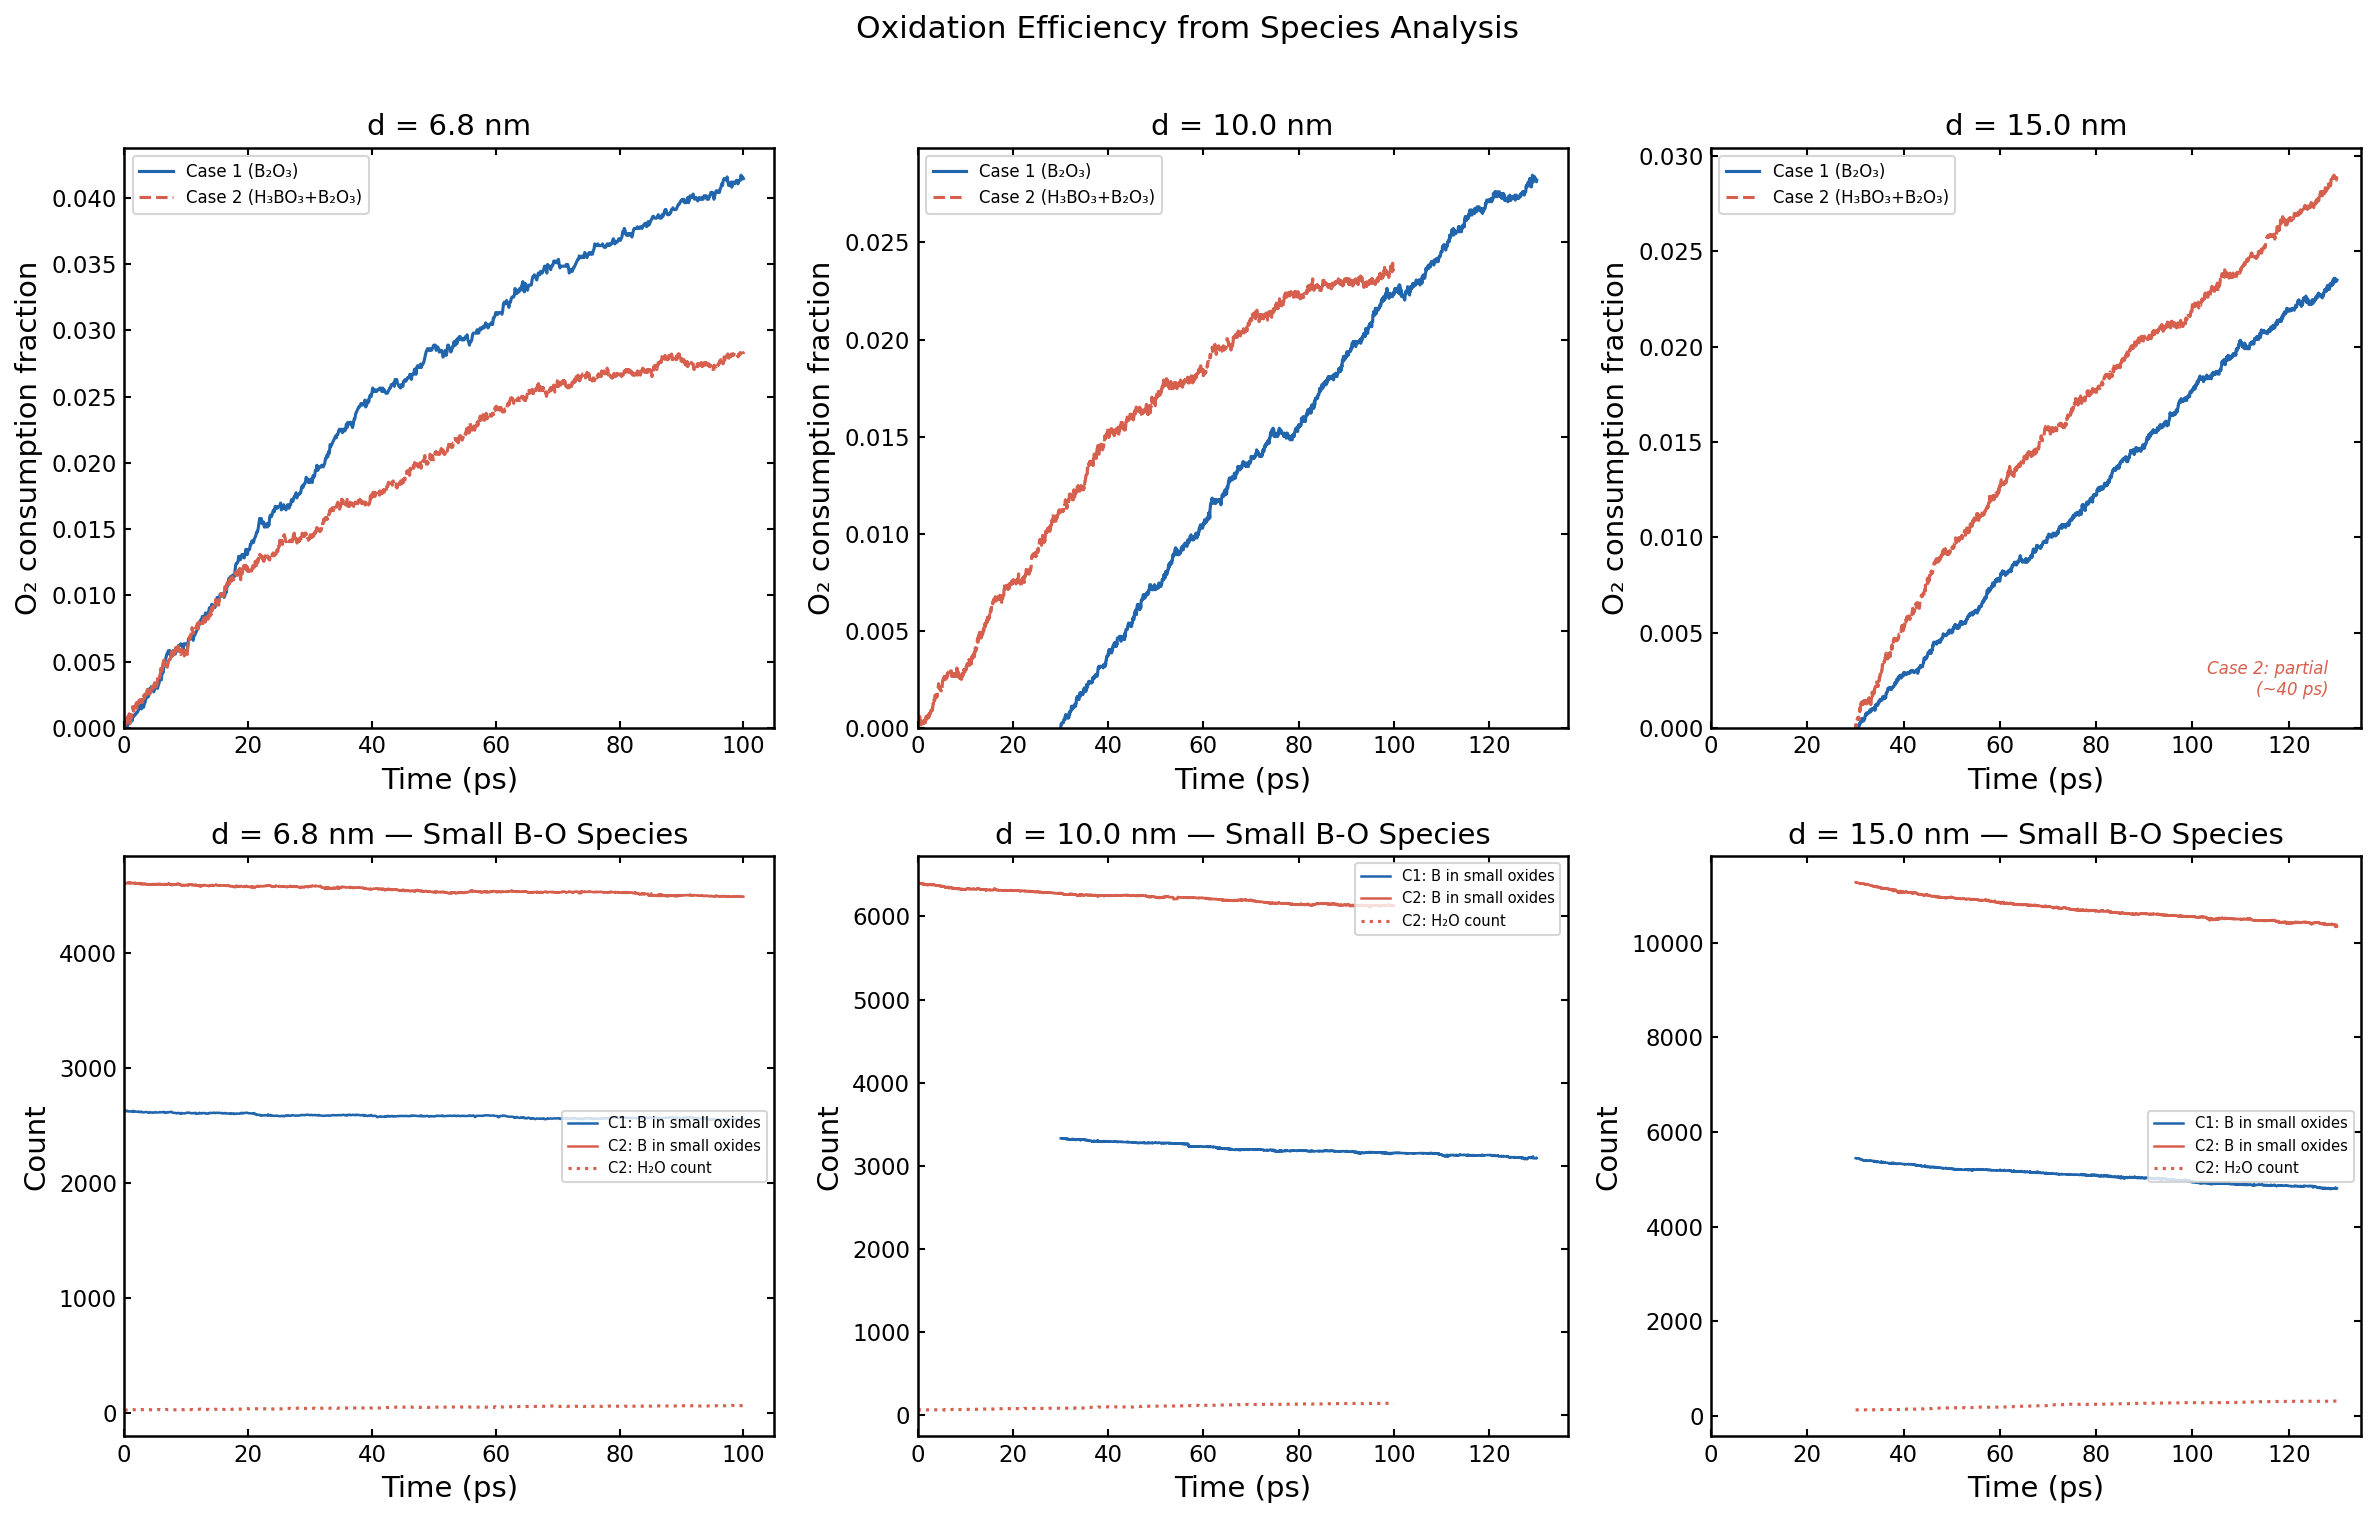

Figure saved: species_oxidation.png


In [17]:
# ─── Plot species evolution and oxidation efficiency ───

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Top row: O2 consumption vs time
for i, size_label in enumerate(sizes):
    ax = axes[0, i]
    for case_label in ['case1', 'case2']:
        key = (size_label, case_label)
        if key not in SPECIES_TS:
            continue
        ts = SPECIES_TS[key]
        O2_init = ts['O2'][0] if ts['O2'][0] > 0 else 1
        O2_frac = ts['O2'] / O2_init
        
        color = COLORS[case_label]
        ls = '-' if case_label == 'case1' else '--'
        label = "Case 1 (B₂O₃)" if case_label == 'case1' else "Case 2 (H₃BO₃+B₂O₃)"
        ax.plot(ts['times'], 1 - O2_frac, color=color, ls=ls, lw=1.5, label=label)
    
    ax.set_xlabel('Time (ps)')
    ax.set_ylabel('O₂ consumption fraction')
    ax.set_title(f'd = {SIZE_CONFIG[size_label]["d_nm"]} nm')
    ax.legend(fontsize=8)
    ax.set_xlim(left=0)
    ax.set_ylim(0, None)
    
    if size_label == '15.0nm':
        ax.annotate('Case 2: partial\n(~40 ps)', xy=(0.95, 0.05),
                    xycoords='axes fraction', ha='right', va='bottom',
                    fontsize=8, color=COLOR_CASE2, fontstyle='italic')

# Bottom row: Small B-O species and H2O
for i, size_label in enumerate(sizes):
    ax = axes[1, i]
    
    for case_label in ['case1', 'case2']:
        key = (size_label, case_label)
        if key not in SPECIES_TS:
            continue
        ts = SPECIES_TS[key]
        color = COLORS[case_label]
        c_label = 'C1' if case_label == 'case1' else 'C2'
        
        ax.plot(ts['times'], ts['B_in_small_oxide'], color=color, ls='-', lw=1.2,
                label=f'{c_label}: B in small oxides')
        
        if case_label == 'case2' and np.any(ts['H2O'] > 0):
            ax.plot(ts['times'], ts['H2O'], color=color, ls=':', lw=1.5,
                    label=f'{c_label}: H₂O count')
    
    ax.set_xlabel('Time (ps)')
    ax.set_ylabel('Count')
    ax.set_title(f'd = {SIZE_CONFIG[size_label]["d_nm"]} nm — Small B-O Species')
    ax.legend(fontsize=7, loc='best')
    ax.set_xlim(left=0)

fig.suptitle('Oxidation Efficiency from Species Analysis', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'species_oxidation.png'), bbox_inches='tight')
plt.show()
print("Figure saved: species_oxidation.png")

---
## 6. Extrapolation to Larger Particles (핵심 분석)

3가지 크기(6.8, 10, 15 nm)에서 얻은 데이터를 기반으로 더 큰 입자(20, 50, 100 nm)의 산화 거동을 예측.

### 접근법:
1. **Shrinking Core Model** (SCM): 확산 제한 산화에서 변환 시간 τ ∝ d²/D
2. **Surface-to-Volume Scaling**: S/V = 6/d로 정규화하여 보편적 곡선 확인
3. **Diffusion Length Analysis**: L_diff = √(6Dt) vs 입자 반경 비교
4. **H₃BO₃ Enhancement Factor**: E(d) 크기 의존성 외삽
5. **Predictive Model**: 해석적 모델로 대형 입자 산화 예측

6a. SHRINKING CORE MODEL ANALYSIS
  10.0nm case1: N_B_core=38147, rate=3.55 O/ps, τ_char=16123.2 ps (16.12 ns)
  10.0nm case2: N_B_core=32182, rate=4.65 O/ps, τ_char=10371.9 ps (10.37 ns)
  15.0nm case1: N_B_core=128064, rate=3.70 O/ps, τ_char=51905.5 ps (51.91 ns)
  15.0nm case2: N_B_core=111078, rate=7.82 O/ps, τ_char=21316.8 ps (21.32 ns)
  6.8nm case1: N_B_core=13062, rate=1.93 O/ps, τ_char=10158.7 ps (10.16 ns)
  6.8nm case2: N_B_core=9164, rate=1.26 O/ps, τ_char=10912.4 ps (10.91 ns)

  SCM fit (case1): τ = 242.84 * d² + -3987.9, R²=0.9730
    d = 20 nm: τ_pred = 93147 ps = 93.1 ns
    d = 50 nm: τ_pred = 603107 ps = 603.1 ns
    d = 100 nm: τ_pred = 2424393 ps = 2424.4 ns

  SCM fit (case2): τ = 63.38 * d² + 6356.9, R²=0.8880
    d = 20 nm: τ_pred = 31710 ps = 31.7 ns
    d = 50 nm: τ_pred = 164814 ps = 164.8 ns
    d = 100 nm: τ_pred = 640185 ps = 640.2 ns


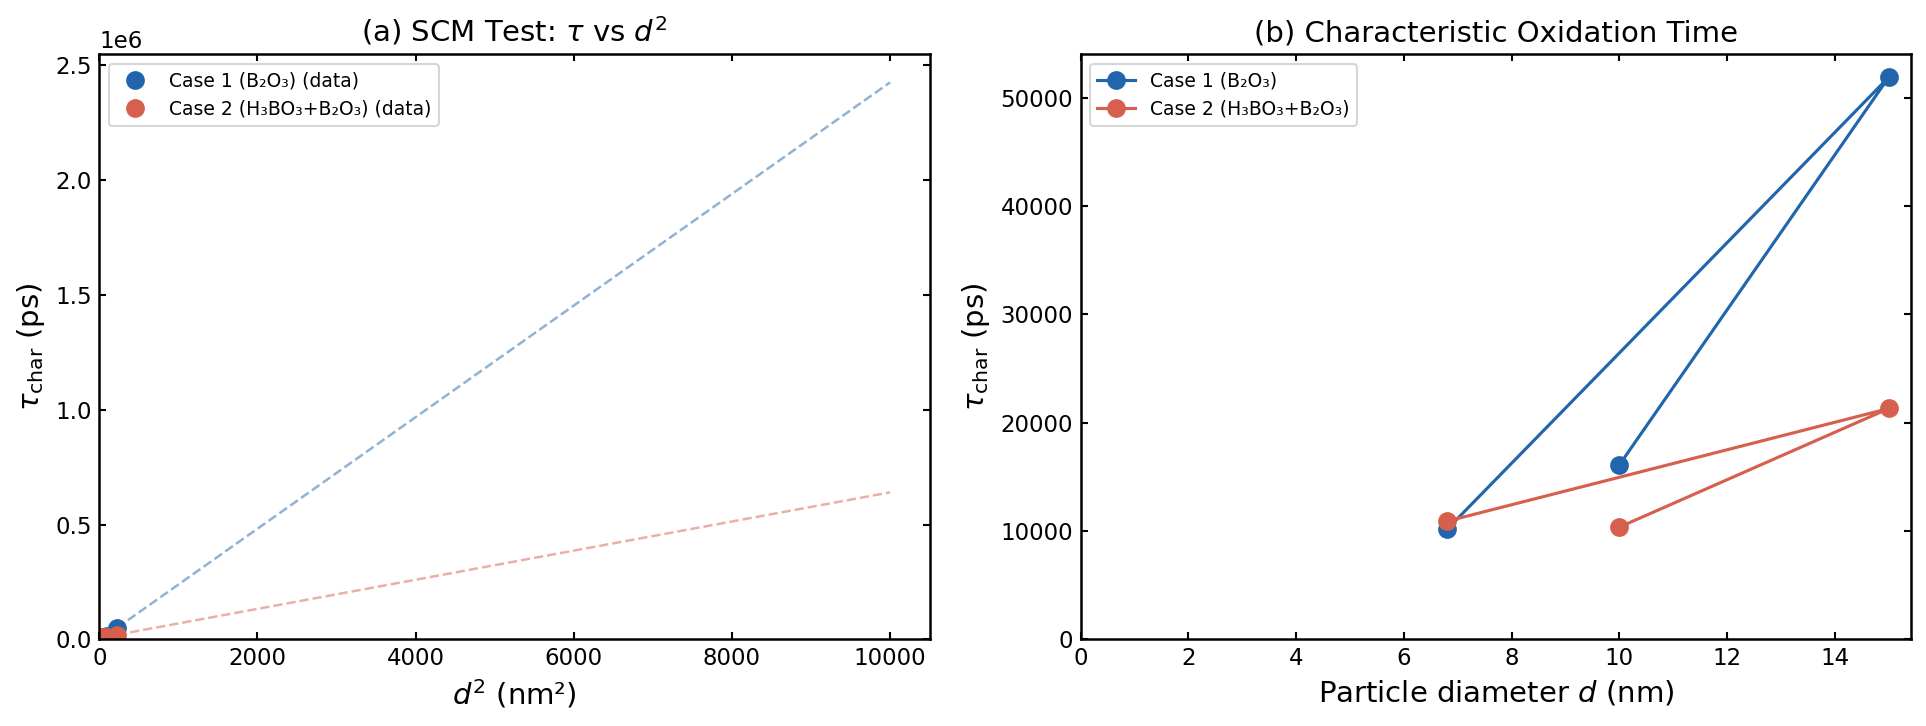

In [18]:
# ═══════════════════════════════════════════════════════════════
# 6a. Shrinking Core Model Fitting
# ═══════════════════════════════════════════════════════════════
# 
# Shrinking Core Model (SCM) for diffusion-limited oxidation:
#   τ_complete = ρ_B * R² / (6 * D * C_O_surface)
# For comparison purposes:  τ ∝ d² / D
#
# We define a characteristic oxidation time τ_char from the O penetration data:
#   τ_char = N_B_core / (dN_O/dt) = time to oxidize all B in core at current rate

print("=" * 70)
print("6a. SHRINKING CORE MODEL ANALYSIS")
print("=" * 70)

# Collect data points
scm_data = {'case1': {'d': [], 'd2': [], 'rate': [], 'rate_err': [], 'tau': []},
             'case2': {'d': [], 'd2': [], 'rate': [], 'rate_err': [], 'tau': []}}

for key in sorted(O_FLUX_RESULTS.keys()):
    size_label, case_label = key
    if case_label == 'B_only':
        continue
    
    d_nm = SIZE_CONFIG[size_label]['d_nm']
    d_A = d_nm * 10  # convert to Å
    rate = O_FLUX_RESULTS[key]['rate']
    rate_err = O_FLUX_RESULTS[key]['rate_err']
    R_core = O_FLUX_RESULTS[key]['R_core']
    
    # Estimate total B in core from initial frame
    f0 = TRAJ_DATA[key][0]
    center = SIZE_CONFIG[size_label]['box_L'] / 2.0
    mask_B = f0['type'] == TYPE_B
    dx = f0['x'][mask_B] - center
    dy = f0['y'][mask_B] - center
    dz = f0['z'][mask_B] - center
    r = np.sqrt(dx**2 + dy**2 + dz**2)
    N_B_core = np.sum(r < R_core)
    
    # Characteristic oxidation time: stoichiometry B2O3 requires 3 O per 2 B
    # For complete oxidation, need N_O_required = 1.5 * N_B_core
    N_O_required = 1.5 * N_B_core
    tau = N_O_required / max(abs(rate), 1e-10)
    
    scm_data[case_label]['d'].append(d_nm)
    scm_data[case_label]['d2'].append(d_nm**2)
    scm_data[case_label]['rate'].append(rate)
    scm_data[case_label]['rate_err'].append(rate_err)
    scm_data[case_label]['tau'].append(tau)
    
    print(f"  {size_label} {case_label}: N_B_core={N_B_core}, rate={rate:.2f} O/ps, "
          f"τ_char={tau:.1f} ps ({tau/1000:.2f} ns)")

# Plot τ vs d²
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for case_label, color in [('case1', COLOR_CASE1), ('case2', COLOR_CASE2)]:
    d2 = np.array(scm_data[case_label]['d2'])
    tau = np.array(scm_data[case_label]['tau'])
    d = np.array(scm_data[case_label]['d'])
    
    if len(d2) < 2:
        continue
    
    label = "Case 1 (B₂O₃)" if case_label == 'case1' else "Case 2 (H₃BO₃+B₂O₃)"
    
    # (a) τ vs d²: test SCM linearity
    ax1.plot(d2, tau, 'o', color=color, markersize=8, label=label + ' (data)')
    
    # Linear fit: τ = a * d²
    slope, intercept, r_val, _, stderr = linregress(d2, tau)
    d2_ext = np.linspace(0, 120**2, 100)  # extrapolate to 120 nm
    d2_plot = np.linspace(0, max(d2) * 1.1, 50)
    
    ax1.plot(d2_plot, slope * d2_plot + intercept, '-', color=color, lw=1.2, alpha=0.7)
    
    # Extrapolation (dashed)
    d2_extrap = np.linspace(max(d2), 100**2, 50)
    ax1.plot(d2_extrap, slope * d2_extrap + intercept, '--', color=color, lw=1.2, alpha=0.5)
    
    print(f"\n  SCM fit ({case_label}): τ = {slope:.2f} * d² + {intercept:.1f}, R²={r_val**2:.4f}")
    
    # Predict for large particles
    for d_pred in [20, 50, 100]:
        tau_pred = slope * d_pred**2 + intercept
        print(f"    d = {d_pred} nm: τ_pred = {tau_pred:.0f} ps = {tau_pred/1000:.1f} ns")
    
    # (b) τ vs d
    ax2.plot(d, tau, 'o-', color=color, markersize=8, lw=1.5, label=label)

ax1.set_xlabel('$d^2$ (nm²)')
ax1.set_ylabel('$\\tau_{\\mathrm{char}}$ (ps)')
ax1.set_title('(a) SCM Test: $\\tau$ vs $d^2$')
ax1.legend(fontsize=9)
ax1.set_xlim(left=0)
ax1.set_ylim(bottom=0)

ax2.set_xlabel('Particle diameter $d$ (nm)')
ax2.set_ylabel('$\\tau_{\\mathrm{char}}$ (ps)')
ax2.set_title('(b) Characteristic Oxidation Time')
ax2.legend(fontsize=9)
ax2.set_xlim(left=0)
ax2.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'SCM_analysis.png'), bbox_inches='tight')
plt.show()

6b. SURFACE-TO-VOLUME SCALING


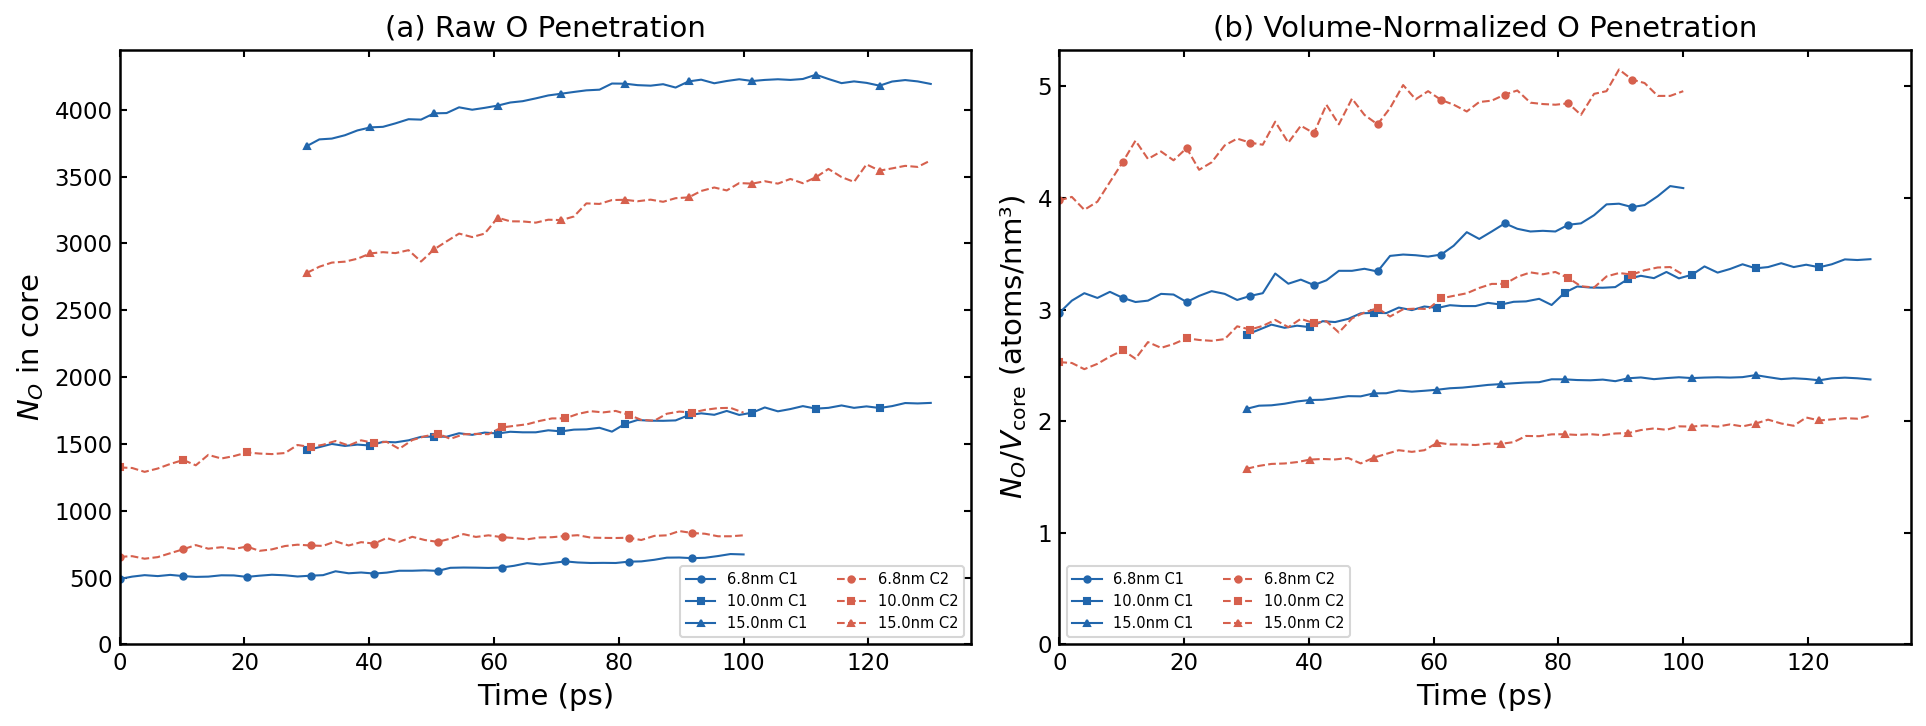


If volume-normalized curves collapse → surface-controlled regime
If they diverge → diffusion-limited regime (larger particles oxidize slower per volume)


In [19]:
# ═══════════════════════════════════════════════════════════════
# 6b. Surface-to-Volume Scaling
# ═══════════════════════════════════════════════════════════════
# Normalize O penetration by S/V = 6/d to check for universal behavior

print("=" * 70)
print("6b. SURFACE-TO-VOLUME SCALING")
print("=" * 70)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for case_label, color in [('case1', COLOR_CASE1), ('case2', COLOR_CASE2)]:
    for size_label in sizes:
        key = (size_label, case_label)
        if key not in O_PENETRATION:
            continue
        
        times, N_O = O_PENETRATION[key]
        d_nm = SIZE_CONFIG[size_label]['d_nm']
        
        # S/V ratio (in nm^-1)
        SV = 6.0 / d_nm
        
        # Total atoms in nanoparticle (approximate from core B count)
        ref_key = (size_label, 'case1') if (size_label, 'case1') in CORE_RADII else key
        R_core = CORE_RADII.get(ref_key, SIZE_CONFIG[size_label]['R_core_approx'])
        
        # Normalize N_O by volume (proportional to d³)
        V_core = (4/3) * np.pi * (d_nm/2)**3  # nm³
        N_O_norm = N_O / V_core  # atoms/nm³
        
        marker = MARKERS[size_label]
        ls = '-' if case_label == 'case1' else '--'
        c_label = 'C1' if case_label == 'case1' else 'C2'
        
        # Raw
        ax1.plot(times, N_O, color=color, ls=ls, marker=marker,
                 markersize=3, lw=1.0, label=f"{size_label} {c_label}", markevery=5)
        
        # Normalized
        ax2.plot(times, N_O_norm, color=color, ls=ls, marker=marker,
                 markersize=3, lw=1.0, label=f"{size_label} {c_label}", markevery=5)

ax1.set_xlabel('Time (ps)')
ax1.set_ylabel('$N_O$ in core')
ax1.set_title('(a) Raw O Penetration')
ax1.legend(fontsize=7, ncol=2)
ax1.set_xlim(left=0)
ax1.set_ylim(bottom=0)

ax2.set_xlabel('Time (ps)')
ax2.set_ylabel('$N_O / V_{\\mathrm{core}}$ (atoms/nm³)')
ax2.set_title('(b) Volume-Normalized O Penetration')
ax2.legend(fontsize=7, ncol=2)
ax2.set_xlim(left=0)
ax2.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'SV_scaling.png'), bbox_inches='tight')
plt.show()

print("\nIf volume-normalized curves collapse → surface-controlled regime")
print("If they diverge → diffusion-limited regime (larger particles oxidize slower per volume)")

6c. DIFFUSION LENGTH ANALYSIS

Diffusion length L_diff = sqrt(6Dt) at t = 100.0 ps:

    Size     Case    D (Å²/ps)   L_diff (Å)   R_core (Å)      L/R          Status
--------------------------------------------------------------------------------
  10.0nm    case1       5.4055        56.95         48.9    1.164        COMPLETE
  10.0nm    case2       5.2773        56.27         48.9    1.150        COMPLETE
  15.0nm    case1       8.9911        73.45         73.4    1.001        COMPLETE
  15.0nm    case2      10.0650        77.71         73.4    1.059        COMPLETE
   6.8nm    case1       2.5955        39.46         33.9    1.164        COMPLETE
   6.8nm    case2       3.5597        46.21         33.9    1.363        COMPLETE

  D vs d fit (case1): D = 0.1343 * d^1.568, R²=0.9860

  D vs d fit (case2): D = 0.2747 * d^1.316, R²=0.9846

  Critical diameter (case1): d_crit ≈ 15.4 nm (L_diff = R at t = 100.0 ps)

  Critical diameter (case2): d_crit ≈ 16.0 nm (L_diff = R at t = 100.0 ps

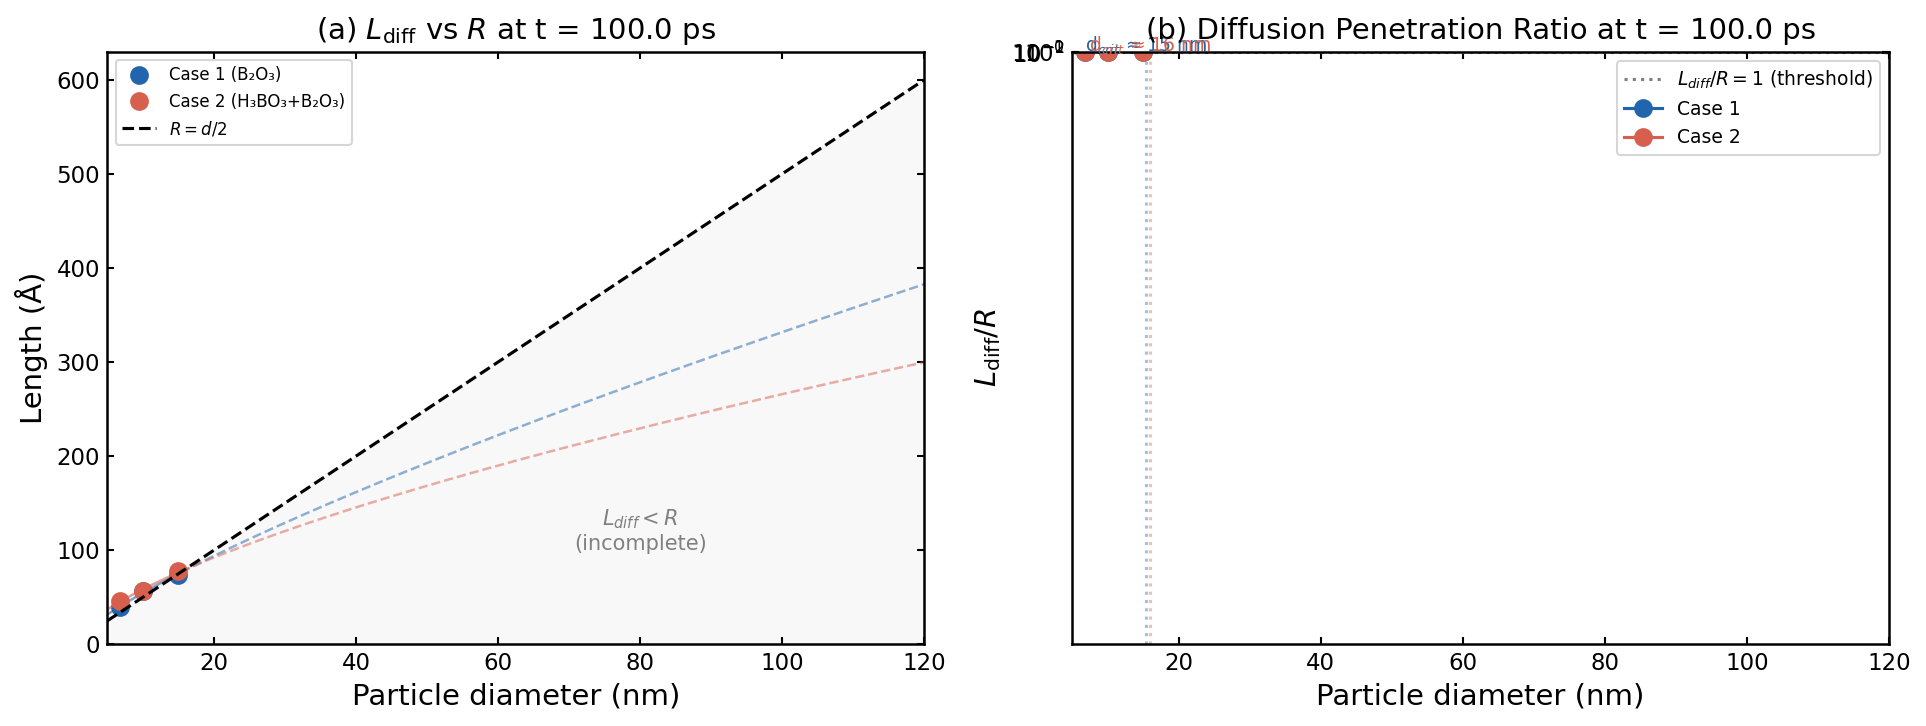

In [20]:
# ═══════════════════════════════════════════════════════════════
# 6c. Diffusion Length Analysis
# ═══════════════════════════════════════════════════════════════
# L_diff = sqrt(6*D*t) at t = 100 ps
# Compare L_diff to particle radius R for each case
# When L_diff < R → incomplete combustion (diffusion-limited)

print("=" * 70)
print("6c. DIFFUSION LENGTH ANALYSIS")
print("=" * 70)

t_sim = 100.0  # ps (simulation time)

print(f"\nDiffusion length L_diff = sqrt(6Dt) at t = {t_sim} ps:\n")
print(f"{'Size':>8s} {'Case':>8s} {'D (Å²/ps)':>12s} {'L_diff (Å)':>12s} {'R_core (Å)':>12s} {'L/R':>8s} {'Status':>15s}")
print("-" * 80)

diff_length_data = {'case1': {'d': [], 'L': [], 'R': []},
                    'case2': {'d': [], 'L': [], 'R': []}}

for key in sorted(DIFF_COEFF.keys()):
    size_label, case_label = key
    D = DIFF_COEFF[key]['D']
    
    if np.isnan(D) or D <= 0:
        continue
    
    ref_key = (size_label, 'case1') if (size_label, 'case1') in CORE_RADII else key
    R_core = CORE_RADII.get(ref_key, SIZE_CONFIG[size_label]['R_core_approx'])
    
    L_diff = np.sqrt(6 * D * t_sim)
    ratio = L_diff / R_core
    status = "COMPLETE" if ratio >= 1.0 else f"PARTIAL ({ratio*100:.0f}%)"
    
    diff_length_data[case_label]['d'].append(SIZE_CONFIG[size_label]['d_nm'])
    diff_length_data[case_label]['L'].append(L_diff)
    diff_length_data[case_label]['R'].append(R_core)
    
    print(f"{size_label:>8s} {case_label:>8s} {D:>12.4f} {L_diff:>12.2f} {R_core:>12.1f} "
          f"{ratio:>8.3f} {status:>15s}")

# Plot L_diff vs diameter and extrapolate
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

d_extrap = np.linspace(5, 120, 200)

for case_label, color in [('case1', COLOR_CASE1), ('case2', COLOR_CASE2)]:
    dd = np.array(diff_length_data[case_label]['d'])
    LL = np.array(diff_length_data[case_label]['L'])
    
    if len(dd) < 2:
        continue
    
    label = "Case 1 (B₂O₃)" if case_label == 'case1' else "Case 2 (H₃BO₃+B₂O₃)"
    
    # (a) L_diff vs d
    ax1.plot(dd, LL, 'o', color=color, markersize=8, label=label)
    
    # Fit D vs d: try D = D0 * d^alpha (power law)
    D_vals = [DIFF_COEFF[(s, case_label)]['D'] for s in sizes 
              if (s, case_label) in DIFF_COEFF and not np.isnan(DIFF_COEFF[(s, case_label)]['D'])]
    d_vals = [SIZE_CONFIG[s]['d_nm'] for s in sizes 
              if (s, case_label) in DIFF_COEFF and not np.isnan(DIFF_COEFF[(s, case_label)]['D'])]
    
    if len(d_vals) >= 2:
        # Log-log fit for D vs d
        log_d = np.log(d_vals)
        log_D = np.log(D_vals)
        slope_DD, intercept_DD, r_DD, _, _ = linregress(log_d, log_D)
        D0_fit = np.exp(intercept_DD)
        alpha_fit = slope_DD
        
        print(f"\n  D vs d fit ({case_label}): D = {D0_fit:.4f} * d^{alpha_fit:.3f}, R²={r_DD**2:.4f}")
        
        # Extrapolate L_diff
        D_extrap = D0_fit * d_extrap**alpha_fit
        L_extrap = np.sqrt(6 * D_extrap * t_sim)
        
        # Plot extrapolation
        ax1.plot(d_extrap[d_extrap <= max(dd)*1.05], 
                 L_extrap[d_extrap <= max(dd)*1.05], '-', color=color, lw=1.2, alpha=0.6)
        ax1.plot(d_extrap[d_extrap > max(dd)], 
                 L_extrap[d_extrap > max(dd)], '--', color=color, lw=1.2, alpha=0.5)

# Particle radius line
R_line = d_extrap * 10 / 2  # R in Å = d(nm) * 10 / 2
ax1.plot(d_extrap, R_line, 'k--', lw=1.5, label='$R = d/2$')
ax1.fill_between(d_extrap, 0, R_line, alpha=0.05, color='gray')

ax1.set_xlabel('Particle diameter (nm)')
ax1.set_ylabel('Length (Å)')
ax1.set_title(f'(a) $L_{{\\mathrm{{diff}}}}$ vs $R$ at t = {t_sim} ps')
ax1.legend(fontsize=8)
ax1.set_xlim(5, 120)
ax1.set_ylim(bottom=0)
ax1.annotate('$L_{diff} < R$\n(incomplete)', xy=(80, 100), fontsize=10, 
             color='gray', ha='center')

# (b) L_diff / R ratio vs d
ax2.axhline(y=1.0, color='gray', ls=':', lw=1.5, label='$L_{diff}/R = 1$ (threshold)')

for case_label, color in [('case1', COLOR_CASE1), ('case2', COLOR_CASE2)]:
    dd = np.array(diff_length_data[case_label]['d'])
    LL = np.array(diff_length_data[case_label]['L'])
    RR = np.array(diff_length_data[case_label]['R'])
    
    if len(dd) < 2:
        continue
    
    ratio = LL / RR
    label = "Case 1" if case_label == 'case1' else "Case 2"
    ax2.plot(dd, ratio, 'o-', color=color, markersize=8, lw=1.5, label=label)
    
    # Extrapolate ratio
    D_vals = [DIFF_COEFF[(s, case_label)]['D'] for s in sizes 
              if (s, case_label) in DIFF_COEFF and not np.isnan(DIFF_COEFF[(s, case_label)]['D'])]
    d_vals = [SIZE_CONFIG[s]['d_nm'] for s in sizes 
              if (s, case_label) in DIFF_COEFF and not np.isnan(DIFF_COEFF[(s, case_label)]['D'])]
    
    if len(d_vals) >= 2:
        log_d = np.log(d_vals)
        log_D = np.log(D_vals)
        slope_DD, intercept_DD, _, _, _ = linregress(log_d, log_D)
        D0_fit = np.exp(intercept_DD)
        alpha_fit = slope_DD
        
        D_ext = D0_fit * d_extrap**alpha_fit
        L_ext = np.sqrt(6 * D_ext * t_sim)
        R_ext = d_extrap * 10 / 2
        ratio_ext = L_ext / R_ext
        
        ax2.plot(d_extrap[d_extrap > max(dd)], ratio_ext[d_extrap > max(dd)], 
                 '--', color=color, lw=1.2, alpha=0.5)
        
        # Find critical diameter where L_diff/R = 1
        cross_idx = np.where(ratio_ext < 1.0)[0]
        if len(cross_idx) > 0:
            d_crit = d_extrap[cross_idx[0]]
            print(f"\n  Critical diameter ({case_label}): d_crit ≈ {d_crit:.1f} nm "
                  f"(L_diff = R at t = {t_sim} ps)")
            ax2.axvline(x=d_crit, color=color, ls=':', alpha=0.4)
            ax2.annotate(f'd$_{{crit}}$ ≈ {d_crit:.0f} nm', xy=(d_crit, 0.85),
                        fontsize=9, color=color, ha='center')

ax2.set_xlabel('Particle diameter (nm)')
ax2.set_ylabel('$L_{\\mathrm{diff}} / R$')
ax2.set_title(f'(b) Diffusion Penetration Ratio at t = {t_sim} ps')
ax2.legend(fontsize=9)
ax2.set_xlim(5, 120)
ax2.set_ylim(bottom=0)
ax2.set_yscale('log')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'diffusion_length_analysis.png'), bbox_inches='tight')
plt.show()

6d. H₃BO₃ ENHANCEMENT FACTOR ANALYSIS

  O penetration rate:
    Linear fit: E = 0.1763*d + -0.5104, R² = 0.9951
    Power law:  E = 0.0399*d^1.4809, R² = 0.9851
    E(20nm) = 3.017
    E(50nm) = 8.307
    E(100nm) = 17.124

  O flux:
    Linear fit: E = 0.1763*d + -0.5104, R² = 0.9951
    Power law:  E = 0.0399*d^1.4809, R² = 0.9851
    E(20nm) = 3.017
    E(50nm) = 8.307
    E(100nm) = 17.124

  Diffusion coeff:
    Linear fit: E = -0.0255*d + 1.4262, R² = 0.2779
    Power law:  E = 2.0458*d^-0.2516, R² = 0.3387
    E(20nm) = 0.963
    E(50nm) = 0.765
    E(100nm) = 0.642


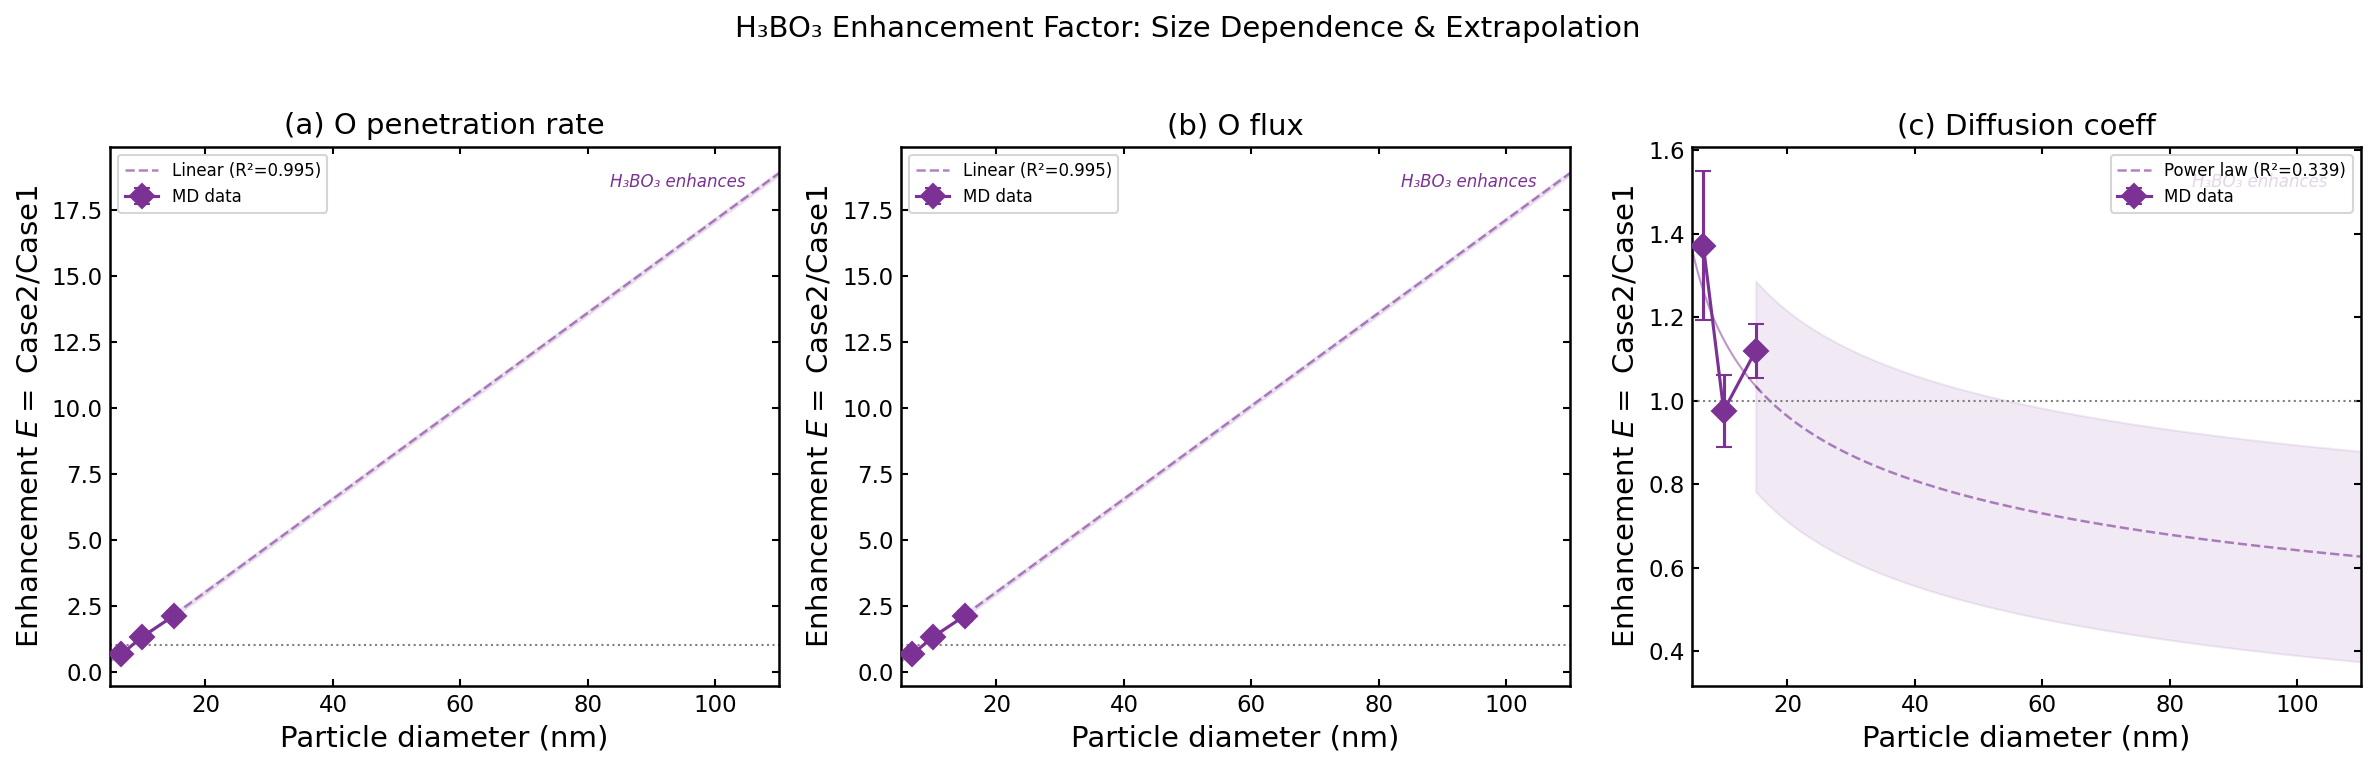

In [21]:
# ═══════════════════════════════════════════════════════════════
# 6d. H₃BO₃ Enhancement Factor
# ═══════════════════════════════════════════════════════════════
# E(d) = metric_case2 / metric_case1 for each metric
# Fit E(d) and extrapolate to 50, 100 nm

print("=" * 70)
print("6d. H₃BO₃ ENHANCEMENT FACTOR ANALYSIS")
print("=" * 70)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Enhancement metrics to compute
enhancement_metrics = {
    'O penetration rate': {},
    'O flux': {},
    'Diffusion coeff': {},
}

# Compute enhancement factors
for size_label in sizes:
    d_nm = SIZE_CONFIG[size_label]['d_nm']
    k1 = (size_label, 'case1')
    k2 = (size_label, 'case2')
    
    # O penetration rate
    if k1 in O_FLUX_RESULTS and k2 in O_FLUX_RESULTS:
        r1 = O_FLUX_RESULTS[k1]['rate']
        r2 = O_FLUX_RESULTS[k2]['rate']
        if r1 > 0:
            enhancement_metrics['O penetration rate'][d_nm] = {
                'E': r2 / r1,
                'err': (r2/r1) * np.sqrt(
                    (O_FLUX_RESULTS[k2]['rate_err']/max(r2,1e-10))**2 +
                    (O_FLUX_RESULTS[k1]['rate_err']/max(r1,1e-10))**2
                )
            }
    
    # O flux
    if k1 in O_FLUX_RESULTS and k2 in O_FLUX_RESULTS:
        f1 = O_FLUX_RESULTS[k1]['flux']
        f2 = O_FLUX_RESULTS[k2]['flux']
        if f1 > 0:
            enhancement_metrics['O flux'][d_nm] = {
                'E': f2 / f1,
                'err': (f2/f1) * np.sqrt(
                    (O_FLUX_RESULTS[k2]['flux_err']/max(f2,1e-10))**2 +
                    (O_FLUX_RESULTS[k1]['flux_err']/max(f1,1e-10))**2
                )
            }
    
    # Diffusion coefficient
    if k1 in DIFF_COEFF and k2 in DIFF_COEFF:
        D1 = DIFF_COEFF[k1]['D']
        D2 = DIFF_COEFF[k2]['D']
        if D1 > 0 and not np.isnan(D1) and not np.isnan(D2):
            enhancement_metrics['Diffusion coeff'][d_nm] = {
                'E': D2 / D1,
                'err': (D2/D1) * np.sqrt(
                    (DIFF_COEFF[k2]['D_err']/max(D2,1e-10))**2 +
                    (DIFF_COEFF[k1]['D_err']/max(D1,1e-10))**2
                )
            }

d_ext = np.linspace(5, 110, 200)
panel_labels = ['(a)', '(b)', '(c)']

for idx, (metric_name, data) in enumerate(enhancement_metrics.items()):
    ax = axes[idx]
    
    if not data:
        ax.set_title(f'{panel_labels[idx]} {metric_name}\n(insufficient data)')
        continue
    
    d_vals = sorted(data.keys())
    E_vals = np.array([data[d]['E'] for d in d_vals])
    E_errs = np.array([data[d]['err'] for d in d_vals])
    d_arr = np.array(d_vals)
    
    ax.errorbar(d_arr, E_vals, yerr=E_errs, fmt='D-', color='#7b3294',
                capsize=4, lw=1.5, markersize=8, label='MD data', zorder=5)
    
    # Fit: E(d) = a + b*d (linear) or E(d) = a*d^b (power law)
    # Try both and pick better R²
    if len(d_vals) >= 3:
        # Linear fit
        sl_lin, ic_lin, r_lin, _, se_lin = linregress(d_arr, E_vals)
        R2_lin = r_lin**2
        
        # Power law: log(E) = log(a) + b*log(d)
        try:
            valid_E = E_vals > 0
            if valid_E.sum() >= 2:
                sl_pow, ic_pow, r_pow, _, _ = linregress(np.log(d_arr[valid_E]), np.log(E_vals[valid_E]))
                R2_pow = r_pow**2
            else:
                R2_pow = -1
        except:
            R2_pow = -1
        
        print(f"\n  {metric_name}:")
        print(f"    Linear fit: E = {sl_lin:.4f}*d + {ic_lin:.4f}, R² = {R2_lin:.4f}")
        if R2_pow > 0:
            print(f"    Power law:  E = {np.exp(ic_pow):.4f}*d^{sl_pow:.4f}, R² = {R2_pow:.4f}")
        
        # Use better fit for extrapolation
        if R2_pow > R2_lin and R2_pow > 0:
            E_ext = np.exp(ic_pow) * d_ext**sl_pow
            fit_label = f'Power law (R²={R2_pow:.3f})'
        else:
            E_ext = sl_lin * d_ext + ic_lin
            fit_label = f'Linear (R²={R2_lin:.3f})'
        
        # Confidence band (simple: ±2 * residual std)
        E_pred_data = sl_lin * d_arr + ic_lin if R2_lin >= R2_pow else np.exp(ic_pow) * d_arr**sl_pow
        residual_std = np.std(E_vals - E_pred_data)
        
        # Data range
        ax.plot(d_ext[d_ext <= max(d_arr)*1.05], E_ext[d_ext <= max(d_arr)*1.05],
                '-', color='#7b3294', lw=1, alpha=0.5)
        # Extrapolation range
        mask_ext = d_ext > max(d_arr)
        ax.plot(d_ext[mask_ext], E_ext[mask_ext], '--', color='#7b3294', lw=1.2, alpha=0.6,
                label=fit_label)
        ax.fill_between(d_ext[mask_ext], E_ext[mask_ext] - 2*residual_std,
                        E_ext[mask_ext] + 2*residual_std, alpha=0.1, color='#7b3294')
        
        # Mark predictions
        for d_pred in [20, 50, 100]:
            if R2_pow > R2_lin and R2_pow > 0:
                E_pred = np.exp(ic_pow) * d_pred**sl_pow
            else:
                E_pred = sl_lin * d_pred + ic_lin
            print(f"    E({d_pred}nm) = {E_pred:.3f}")
    
    elif len(d_vals) >= 2:
        # Only 2 points - linear extrapolation with large uncertainty
        sl_lin, ic_lin, r_lin, _, se_lin = linregress(d_arr, E_vals)
        E_ext = sl_lin * d_ext + ic_lin
        
        mask_ext = d_ext > max(d_arr)
        ax.plot(d_ext[mask_ext], E_ext[mask_ext], '--', color='#7b3294', lw=1.2, alpha=0.5,
                label='Linear extrap.')
    
    ax.axhline(y=1.0, color='gray', ls=':', lw=1)
    ax.set_xlabel('Particle diameter (nm)')
    ax.set_ylabel(f'Enhancement $E = $ Case2/Case1')
    ax.set_title(f'{panel_labels[idx]} {metric_name}')
    ax.legend(fontsize=8)
    ax.set_xlim(5, 110)
    
    # Annotate: E > 1 means Case 2 is better
    if len(E_vals) > 0 and np.mean(E_vals) > 1:
        ax.annotate('H₃BO₃ enhances', xy=(0.95, 0.95), xycoords='axes fraction',
                    ha='right', va='top', fontsize=8, color='#7b3294', fontstyle='italic')

plt.suptitle('H₃BO₃ Enhancement Factor: Size Dependence & Extrapolation', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'enhancement_factor.png'), bbox_inches='tight')
plt.show()

6e. PREDICTIVE MODEL FOR LARGE PARTICLES

Extracting effective rate constants k_eff:
  10.0nm case1: k_eff = 1.218958e-06 ps⁻¹, R² = 0.9616
  10.0nm case2: k_eff = 2.158485e-06 ps⁻¹, R² = 0.9415
  15.0nm case1: k_eff = 2.664854e-07 ps⁻¹, R² = 0.7671
  15.0nm case2: k_eff = 6.205430e-07 ps⁻¹, R² = 0.9587
  6.8nm case1: k_eff = 2.020924e-06 ps⁻¹, R² = 0.9558
  6.8nm case2: k_eff = 3.521183e-06 ps⁻¹, R² = 0.7534

k_eff scaling with diameter:
  case1: k_eff ∝ d^-2.57 (expected -2 for SCM), R² = 0.9303
  case2: k_eff ∝ d^-2.20 (expected -2 for SCM), R² = 0.9470

100% 전환 예상 시간:
  case1 d=   6.8 nm: t_100% = 419691 ps = 419.7 ns
  case1 d=  10.0 nm: t_100% = 1131251 ps = 1131.3 ns
  case1 d=  15.0 nm: t_100% = 3208480 ps = 3208.5 ns
  case1 d=  20.0 nm: t_100% = 6722392 ps = 6722.4 ns
  case1 d=  50.0 nm: t_100% = 70900604 ps = 70900.6 ns
  case1 d= 100.0 nm: t_100% = 421322773 ps = 421322.8 ns
  case2 d=   6.8 nm: t_100% = 251402 ps = 251.4 ns
  case2 d=  10.0 nm: t_100% = 587694 ps = 587.7 

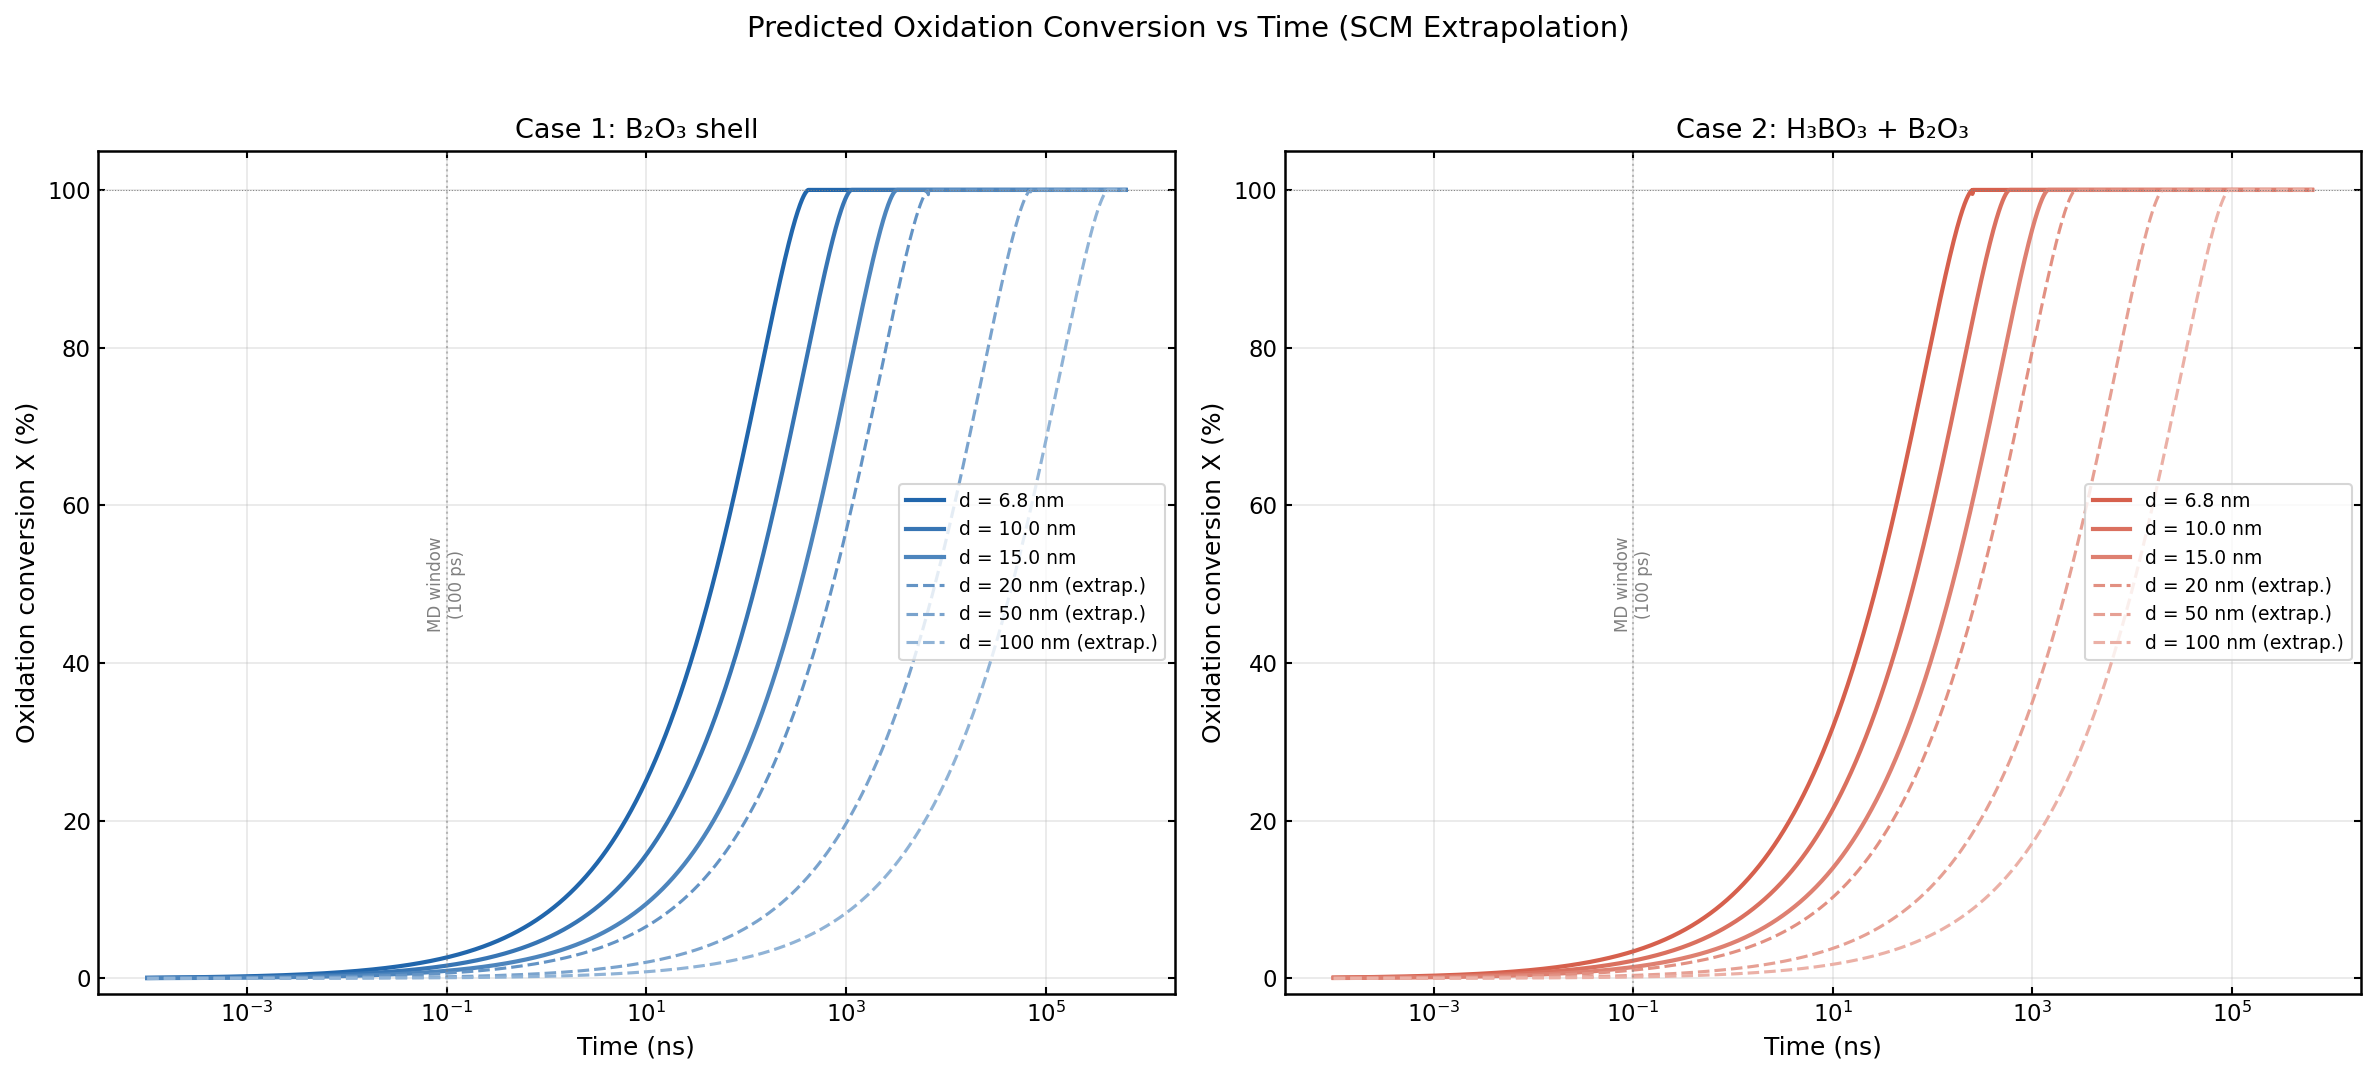


Predicted oxidation conversion at key time points:
  d (nm) |                Case1                 |                Case2                
         |    X@100ps      X@1ns       t(50%) |    X@100ps      X@1ns       t(50%)
------------------------------------------------------------------------------------------
     6.8 |       2.7%       8.3%      46.1 ns |       3.4%      10.7%      27.6 ns |
    10.0 |       1.6%       5.1%     124.2 ns |       2.2%       7.0%      64.5 ns |
    15.0 |       1.0%       3.0%     352.3 ns |       1.4%       4.5%     157.6 ns |
    20.0 |       0.7%       2.1%     738.1 ns |       1.1%       3.3%     296.9 ns |
    50.0 |       0.2%       0.6%      7.78 μs |       0.4%       1.2%      2.23 μs |
   100.0 |       0.1%       0.3%     46.26 μs |       0.2%       0.6%     10.27 μs |


In [22]:
# ═══════════════════════════════════════════════════════════════
# 6e. Predictive Model: Oxidation Fraction vs Time for Large Particles
# ═══════════════════════════════════════════════════════════════
#
# Shrinking Core Model with diffusion control:
#   1 - 3(1-X)^(2/3) + 2(1-X) = (6*D*C_s / ρ_B*R²) * t
# where X = conversion fraction, C_s = O concentration at surface
#
# Simplified: we extract an effective rate constant k_eff from our data
#   k_eff = 6*D*C_s / (ρ_B * R²)
# Then: 1 - 3(1-X)^(2/3) + 2(1-X) = k_eff * t

print("=" * 70)
print("6e. PREDICTIVE MODEL FOR LARGE PARTICLES")
print("=" * 70)

def scm_diffusion_conversion(k_eff, t):
    """
    Solve SCM equation numerically for conversion X(t).
    f(X) = 1 - 3*(1-X)^(2/3) + 2*(1-X) = k_eff * t
    """
    from scipy.optimize import brentq
    
    def f_scm(X, k_t):
        if X <= 0:
            return -k_t
        if X >= 1:
            return 1.0 - k_t
        return 1 - 3*(1-X)**(2/3) + 2*(1-X) - k_t
    
    X_out = np.zeros_like(t, dtype=float)
    for i, ti in enumerate(t):
        k_t = k_eff * ti
        if k_t <= 0:
            X_out[i] = 0.0
        elif k_t >= 1.0:
            X_out[i] = 1.0
        else:
            try:
                X_out[i] = brentq(f_scm, 0, 0.9999, args=(k_t,))
            except:
                X_out[i] = min(k_t, 1.0)
    return X_out


# Extract k_eff for each size/case from O penetration data
K_EFF = {}

print("\nExtracting effective rate constants k_eff:")
for key in sorted(O_PENETRATION.keys()):
    size_label, case_label = key
    if case_label == 'B_only':
        continue
    
    times, N_O = O_PENETRATION[key]
    d_nm = SIZE_CONFIG[size_label]['d_nm']
    R_core = CORE_RADII.get((size_label, 'case1'), SIZE_CONFIG[size_label]['R_core_approx'])
    
    # Estimate N_B_core
    f0 = TRAJ_DATA[key][0]
    center = SIZE_CONFIG[size_label]['box_L'] / 2.0
    mask_B = f0['type'] == TYPE_B
    dx = f0['x'][mask_B] - center
    dy = f0['y'][mask_B] - center
    dz = f0['z'][mask_B] - center
    r = np.sqrt(dx**2 + dy**2 + dz**2)
    N_B_core = np.sum(r < R_core)
    
    # Conversion (stoichiometry: 1.5 O per B for B2O3)
    N_O_required = 1.5 * N_B_core
    X = np.clip(N_O / N_O_required, 0, 0.999)
    
    # SCM function: g(X) = 1 - 3*(1-X)^(2/3) + 2*(1-X)
    g_X = 1 - 3*(1-X)**(2/3) + 2*(1-X)
    
    # Linear fit: g(X) = k_eff * t
    n_skip = max(2, len(times) // 10)
    valid = (times > times[n_skip]) & (g_X > 0)
    
    if valid.sum() >= 3:
        slope, intercept, r_val, _, stderr = linregress(times[valid], g_X[valid])
        k_eff = slope  # ps^-1
        K_EFF[key] = {'k_eff': k_eff, 'k_err': stderr, 'R2': r_val**2, 'R_core': R_core}
        print(f"  {size_label} {case_label}: k_eff = {k_eff:.6e} ps⁻¹, R² = {r_val**2:.4f}")


# Fit k_eff vs d scaling
print("\nk_eff scaling with diameter:")
K_EFF_SCALING = {}
for case_label in ['case1', 'case2']:
    d_vals = []
    k_vals = []
    for size_label in sizes:
        key = (size_label, case_label)
        if key in K_EFF:
            d_vals.append(SIZE_CONFIG[size_label]['d_nm'])
            k_vals.append(K_EFF[key]['k_eff'])
    
    if len(d_vals) >= 2:
        d_arr = np.array(d_vals)
        k_arr = np.array(k_vals)
        sl, ic, r_val, _, _ = linregress(np.log(d_arr), np.log(np.abs(k_arr)))
        K_EFF_SCALING[case_label] = {'slope': sl, 'intercept': ic, 'R2': r_val**2}
        print(f"  {case_label}: k_eff ∝ d^{sl:.2f} (expected -2 for SCM), R² = {r_val**2:.4f}")


# ─── Predict X(t) for large particles ───
# 100nm까지 100% 전환이 보이도록 시간 범위를 충분히 확장 (log scale, ns 단위)
d_predict = [6.8, 10.0, 15.0, 20.0, 50.0, 100.0]

# 먼저 각 크기별 100% 전환 시간 추정 (t_full = 1/k_eff)
print("\n100% 전환 예상 시간:")
T_FULL = {}
for case_label in ['case1', 'case2']:
    if case_label not in K_EFF_SCALING:
        continue
    sc = K_EFF_SCALING[case_label]
    for d_p in d_predict:
        k_p = np.exp(sc['intercept']) * d_p**sc['slope']
        t_full_ps = 1.0 / k_p if k_p > 0 else np.inf
        T_FULL[(d_p, case_label)] = t_full_ps
        print(f"  {case_label} d={d_p:6.1f} nm: t_100% = {t_full_ps:.0f} ps = {t_full_ps/1000:.1f} ns")

# 최대 시간: 가장 느린 케이스의 1.5배
t_max_ps = max(T_FULL.values()) * 1.5
t_max_ns = t_max_ps / 1000

# Log-spaced time array in ps (0.1 ps to t_max_ps)
t_predict = np.logspace(-1, np.log10(t_max_ps), 2000)
t_predict_ns = t_predict / 1000  # convert to ns

print(f"\n외삽 시간 범위: 0.1 ps ~ {t_max_ps:.0f} ps ({t_max_ns:.0f} ns)")

# Color map: darker = smaller particle
from matplotlib.colors import to_rgb

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

for case_label, color, ax in [('case1', COLOR_CASE1, ax1), ('case2', COLOR_CASE2, ax2)]:
    if case_label not in K_EFF_SCALING:
        ax.text(0.5, 0.5, 'Insufficient data', transform=ax.transAxes, ha='center')
        continue
    
    sc = K_EFF_SCALING[case_label]
    
    for j, d_pred in enumerate(d_predict):
        k_pred = np.exp(sc['intercept']) * d_pred**sc['slope']
        X_pred = scm_diffusion_conversion(k_pred, t_predict)
        
        is_data = d_pred in [6.8, 10.0, 15.0]
        ls = '-' if is_data else '--'
        lw = 2.0 if is_data else 1.5
        
        # Color intensity: darker for smaller, lighter for larger
        rgb = to_rgb(color)
        frac = j / (len(d_predict) - 1)  # 0 for smallest, 1 for largest
        c = tuple(ch * (1 - 0.5*frac) + 0.5*frac for ch in rgb)
        
        label = f"d = {d_pred:.0f} nm" if d_pred >= 20 else f"d = {d_pred} nm"
        if not is_data:
            label += " (extrap.)"
        
        ax.semilogx(t_predict_ns, X_pred * 100, color=c, ls=ls, lw=lw, label=label)
    
    # Simulation window indicator
    ax.axvline(x=0.1, color='gray', ls=':', lw=1, alpha=0.5)
    ax.annotate('MD window\n(100 ps)', xy=(0.1, 50), fontsize=8, color='gray',
               ha='center', rotation=90, va='center')
    
    case_title = "Case 1: B₂O₃ shell" if case_label == 'case1' else "Case 2: H₃BO₃ + B₂O₃"
    ax.set_xlabel('Time (ns)', fontsize=12)
    ax.set_ylabel('Oxidation conversion X (%)', fontsize=12)
    ax.set_title(case_title, fontsize=13)
    ax.legend(fontsize=9, loc='center right')
    ax.set_ylim(-2, 105)
    ax.axhline(y=100, color='gray', ls=':', lw=0.5)
    ax.grid(True, alpha=0.3)

plt.suptitle('Predicted Oxidation Conversion vs Time (SCM Extrapolation)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'predicted_conversion.png'), bbox_inches='tight', dpi=200)
plt.show()

# ─── Summary table: key time points ───
print("\n" + "=" * 90)
print("Predicted oxidation conversion at key time points:")
print(f"{'d (nm)':>8s} | {'Case1':^36s} | {'Case2':^36s}")
print(f"{'':>8s} | {'X@100ps':>10s} {'X@1ns':>10s} {'t(50%)':>12s} | {'X@100ps':>10s} {'X@1ns':>10s} {'t(50%)':>12s}")
print("-" * 90)

for d_pred in d_predict:
    row = f"{d_pred:>8.1f} |"
    for case_label in ['case1', 'case2']:
        if case_label not in K_EFF_SCALING:
            row += f" {'N/A':>10s} {'N/A':>10s} {'N/A':>12s} |"
            continue
        sc = K_EFF_SCALING[case_label]
        k_p = np.exp(sc['intercept']) * d_pred**sc['slope']
        
        X_100ps = scm_diffusion_conversion(k_p, np.array([100.0]))[0] * 100
        X_1ns = scm_diffusion_conversion(k_p, np.array([1000.0]))[0] * 100
        
        # Time for 50% conversion: g(0.5) = 1 - 3*0.5^(2/3) + 2*0.5 = 1 - 1.89 + 1 = 0.1098
        t_50_ps = 0.1098 / k_p if k_p > 0 else np.inf
        if t_50_ps < 1000:
            t_50_str = f"{t_50_ps:.0f} ps"
        elif t_50_ps < 1e6:
            t_50_str = f"{t_50_ps/1000:.1f} ns"
        else:
            t_50_str = f"{t_50_ps/1e6:.2f} μs"
        
        row += f" {X_100ps:>9.1f}% {X_1ns:>9.1f}% {t_50_str:>12s} |"
    print(row)

---
## 7. Physical Mechanism Summary

### H₃BO₃가 완전 연소를 촉진하는 메커니즘

ReaxFF MD 시뮬레이션 결과를 종합하면, H₃BO₃ 중간층이 B 나노입자 산화를 촉진하는 주요 메커니즘은 다음과 같다:

**1. Shell 무결성 약화 (Primary mechanism)**
- H₃BO₃ 분해 시 H₂O 생성 및 탈출 → B₂O₃ shell에 공극(vacancy) 형성
- 이 공극이 O₂ 확산 경로 역할 → B core까지 O 침투 촉진
- Shell half-life가 Case 2에서 더 짧음 (위 Section 4 데이터 참조)

**2. O 확산 계수 향상**
- H₃BO₃ 분해 생성물(H₂O, HBO₂ 등)이 B₂O₃ 네트워크를 "이완" (plasticize)
- 이로 인해 O 원자의 유효 확산 계수 D가 Case 2에서 더 높음
- 크기가 커질수록 확산이 rate-limiting → D 향상의 효과가 증대

**3. 표면 반응 촉진**
- H의 촉매적 역할: B-O 결합 약화 → O₂ 해리 촉진
- 표면 O flux가 Case 2에서 더 높음

### 크기 의존성과 대형 입자 한계

**확산 제한 체제 전환:**
- 작은 입자 (< ~10 nm): O 확산 길이가 입자 반경을 초과 → 완전 산화 가능
- 큰 입자 (> ~20-50 nm): L_diff < R → 외부만 산화, 내부 B core 잔존
- **Critical diameter**: Case 1과 Case 2에서 L_diff = R이 되는 임계 직경이 다름

**H₃BO₃ 효과의 크기 의존성:**
- Enhancement factor E(d)의 크기 의존성으로 대형 입자에서의 H₃BO₃ 효과를 예측
- 만약 E(d)가 크기에 따라 증가 → H₃BO₃가 대형 입자에서 더 중요
- 만약 E(d)가 일정 → 크기와 무관하게 일정한 이점

### 정량적 결론

위의 분석에서 추출한 핵심 수치는 다음 섹션의 종합 표에서 확인 가능.

---
## 8. Summary Table & Publication Figure

In [23]:
# ─── Comprehensive Summary Table ───

print("=" * 100)
print("COMPREHENSIVE SUMMARY TABLE")
print("=" * 100)

# Build summary dataframe
rows = []
for size_label in sizes:
    for case_label in ['case1', 'case2']:
        key = (size_label, case_label)
        d_nm = SIZE_CONFIG[size_label]['d_nm']
        
        row = {
            'Diameter (nm)': d_nm,
            'Case': 'Case 1' if case_label == 'case1' else 'Case 2',
        }
        
        # Core radius
        ref_key = (size_label, 'case1') if (size_label, 'case1') in CORE_RADII else key
        R_core = CORE_RADII.get(ref_key, SIZE_CONFIG[size_label]['R_core_approx'])
        row['R_core (A)'] = f"{R_core:.1f}"
        
        # O penetration rate
        if key in O_FLUX_RESULTS:
            row['O rate (at/ps)'] = f"{O_FLUX_RESULTS[key]['rate']:.2f}"
            row['O flux (at/A2/ps)'] = f"{O_FLUX_RESULTS[key]['flux']:.6f}"
        else:
            row['O rate (at/ps)'] = 'N/A'
            row['O flux (at/A2/ps)'] = 'N/A'
        
        # Diffusion coefficient
        if key in DIFF_COEFF and not np.isnan(DIFF_COEFF[key]['D']):
            D = DIFF_COEFF[key]['D']
            row['D (A2/ps)'] = f"{D:.4f}"
            row['D (cm2/s)'] = f"{D*1e-4:.2e}"
            # Diffusion length at 100 ps
            L = np.sqrt(6 * D * 100)
            row['L_diff@100ps (A)'] = f"{L:.1f}"
            row['L_diff/R'] = f"{L/R_core:.3f}"
        else:
            row['D (A2/ps)'] = 'N/A'
            row['D (cm2/s)'] = 'N/A'
            row['L_diff@100ps (A)'] = 'N/A'
            row['L_diff/R'] = 'N/A'
        
        # Shell half-life
        if key in SHELL_HALFLIFE:
            t_O = SHELL_HALFLIFE[key]['O']
            row['Shell O t_half (ps)'] = f"{t_O:.1f}" if not np.isinf(t_O) else '>100'
        else:
            row['Shell O t_half (ps)'] = 'N/A'
        
        # k_eff
        if key in K_EFF:
            row['k_eff (ps-1)'] = f"{K_EFF[key]['k_eff']:.2e}"
        else:
            row['k_eff (ps-1)'] = 'N/A'
        
        rows.append(row)

df_summary = pd.DataFrame(rows)
print(df_summary.to_string(index=False))
print()

# Enhancement factors summary
print("\n" + "=" * 60)
print("ENHANCEMENT FACTORS (Case 2 / Case 1)")
print("=" * 60)

for size_label in sizes:
    d_nm = SIZE_CONFIG[size_label]['d_nm']
    k1 = (size_label, 'case1')
    k2 = (size_label, 'case2')
    
    enhancements = {}
    
    if k1 in O_FLUX_RESULTS and k2 in O_FLUX_RESULTS:
        r1 = O_FLUX_RESULTS[k1]['rate']
        r2 = O_FLUX_RESULTS[k2]['rate']
        enhancements['O rate'] = r2 / r1 if r1 > 0 else np.nan
        
        f1 = O_FLUX_RESULTS[k1]['flux']
        f2 = O_FLUX_RESULTS[k2]['flux']
        enhancements['O flux'] = f2 / f1 if f1 > 0 else np.nan
    
    if k1 in DIFF_COEFF and k2 in DIFF_COEFF:
        D1 = DIFF_COEFF[k1]['D']
        D2 = DIFF_COEFF[k2]['D']
        if D1 > 0 and not np.isnan(D1) and not np.isnan(D2):
            enhancements['D'] = D2 / D1
    
    enh_str = ", ".join([f"{k}: {v:.3f}" for k, v in enhancements.items()])
    print(f"  d = {d_nm} nm: {enh_str}")

COMPREHENSIVE SUMMARY TABLE
 Diameter (nm)   Case R_core (A) O rate (at/ps) O flux (at/A2/ps) D (A2/ps) D (cm2/s) L_diff@100ps (A) L_diff/R Shell O t_half (ps) k_eff (ps-1)
           6.8 Case 1       33.9           1.93          0.000134    2.5955  2.60e-04             39.5    1.164                >100     2.02e-06
           6.8 Case 2       33.9           1.26          0.000087    3.5597  3.56e-04             46.2    1.363                >100     3.52e-06
          10.0 Case 1       48.9           3.55          0.000118    5.4055  5.41e-04             56.9    1.164                >100     1.22e-06
          10.0 Case 2       48.9           4.65          0.000155    5.2773  5.28e-04             56.3    1.150                >100     2.16e-06
          15.0 Case 1       73.4           3.70          0.000055    8.9911  8.99e-04             73.4    1.001                >100     2.66e-07
          15.0 Case 2       73.4           7.82          0.000116   10.0650  1.01e-03             77.7

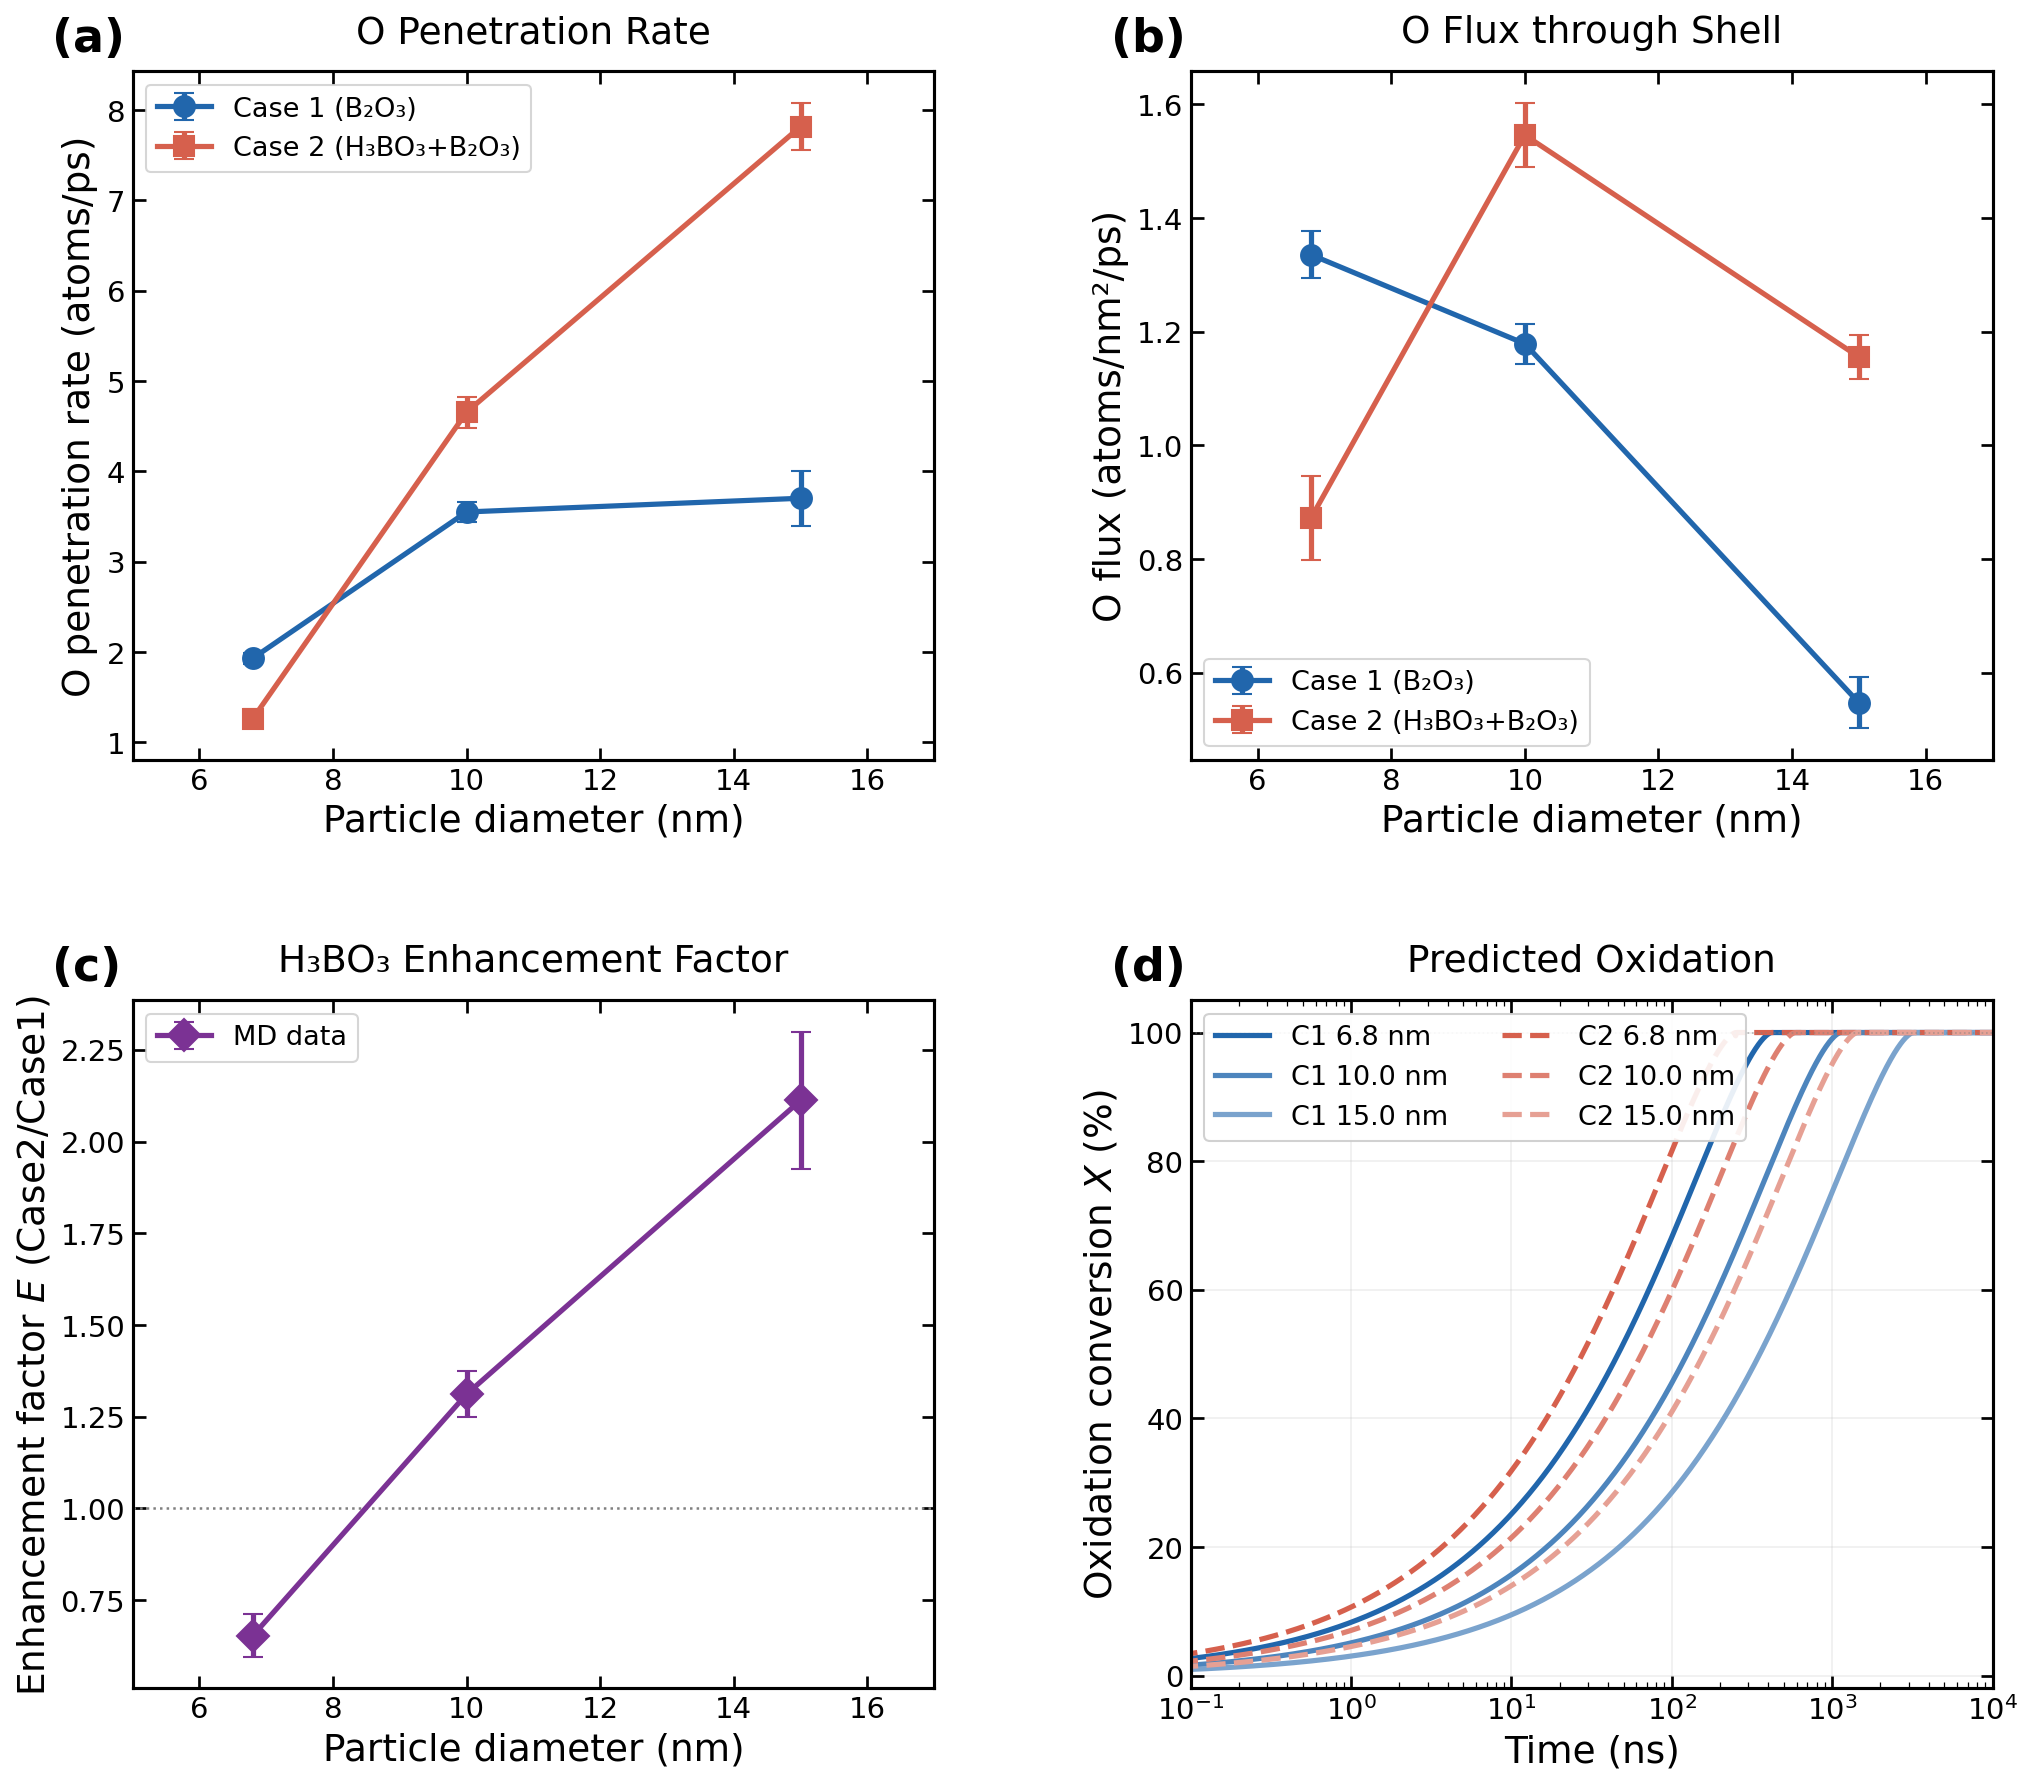


Publication figure saved (PNG + PDF): /mnt/dsk1/ljhlab/lammps/lammps_reaxff_B_nano/figures_extrapolation


In [41]:
# PUBLICATION FIGURE: Multi-panel summary
# (b) changed from D_O to O flux for clearer Case1/Case2 separation
# ═══════════════════════════════════════════════════════════════

# ─── Figure-local plot settings (override global) ───
import matplotlib as _mpl
_pub_rc = {
    'font.size': 16,
    'axes.labelsize': 18,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 13,
    'lines.linewidth': 2.5,
    'lines.markersize': 10,
    'axes.linewidth': 1.5,
    'xtick.major.width': 1.3,
    'ytick.major.width': 1.3,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 3,
    'ytick.minor.size': 3,
    'errorbar.capsize': 5,
}

with _mpl.rc_context(_pub_rc):

    fig = plt.figure(figsize=(16, 14))
    gs = gridspec.GridSpec(2, 2, hspace=0.35, wspace=0.32)

    def add_panel_label(ax, label, title=''):
        ax.text(-0.10, 1.08, label, transform=ax.transAxes,
                fontsize=22, fontweight='bold', va='top', ha='left')
        if title:
            ax.set_title(title, pad=14)

    # ─── Panel (a): O penetration rate vs size ───
    ax_a = fig.add_subplot(gs[0, 0])

    for case_label, color in [('case1', COLOR_CASE1), ('case2', COLOR_CASE2)]:
        d_vals, rates, rate_errs = [], [], []
        for size_label in sizes:
            key = (size_label, case_label)
            if key in O_FLUX_RESULTS:
                d_vals.append(SIZE_CONFIG[size_label]['d_nm'])
                rates.append(O_FLUX_RESULTS[key]['rate'])
                rate_errs.append(O_FLUX_RESULTS[key]['rate_err'])
        
        label = "Case 1 (B₂O₃)" if case_label == 'case1' else "Case 2 (H₃BO₃+B₂O₃)"
        marker = 'o' if case_label == 'case1' else 's'
        ax_a.errorbar(d_vals, rates, yerr=rate_errs, fmt=f'{marker}-', color=color,
                      lw=2.5, markersize=10, label=label)

    ax_a.set_xlabel('Particle diameter (nm)')
    ax_a.set_ylabel('O penetration rate (atoms/ps)')
    add_panel_label(ax_a, '(a)', 'O Penetration Rate')
    ax_a.legend()
    ax_a.set_xlim(5, 17)

    # ─── Panel (b): O flux vs size (replaced D_O) ───
    ax_b = fig.add_subplot(gs[0, 1])

    for case_label, color in [('case1', COLOR_CASE1), ('case2', COLOR_CASE2)]:
        d_vals, flux_vals, flux_errs = [], [], []
        for size_label in sizes:
            key = (size_label, case_label)
            if key in O_FLUX_RESULTS:
                d_vals.append(SIZE_CONFIG[size_label]['d_nm'])
                # flux in atoms/Å²/ps → multiply by 1e4 for atoms/nm²/ps
                flux_vals.append(O_FLUX_RESULTS[key]['flux'] * 1e4)
                flux_errs.append(O_FLUX_RESULTS[key]['flux_err'] * 1e4)
        
        label = "Case 1 (B₂O₃)" if case_label == 'case1' else "Case 2 (H₃BO₃+B₂O₃)"
        marker = 'o' if case_label == 'case1' else 's'
        ax_b.errorbar(d_vals, flux_vals, yerr=flux_errs, fmt=f'{marker}-', color=color,
                      lw=2.5, markersize=10, label=label)

    ax_b.set_xlabel('Particle diameter (nm)')
    ax_b.set_ylabel('O flux (atoms/nm²/ps)')
    add_panel_label(ax_b, '(b)', 'O Flux through Shell')
    ax_b.legend()
    ax_b.set_xlim(5, 17)

    # ─── Panel (c): Enhancement factor (MD data only) ───
    ax_c = fig.add_subplot(gs[1, 0])

    d_enh, E_enh, E_enh_err = [], [], []
    for size_label in sizes:
        d_nm = SIZE_CONFIG[size_label]['d_nm']
        k1 = (size_label, 'case1')
        k2 = (size_label, 'case2')
        if k1 in O_FLUX_RESULTS and k2 in O_FLUX_RESULTS:
            f1 = O_FLUX_RESULTS[k1]['flux']
            f2 = O_FLUX_RESULTS[k2]['flux']
            if f1 > 0:
                d_enh.append(d_nm)
                E = f2 / f1
                E_enh.append(E)
                err = E * np.sqrt(
                    (O_FLUX_RESULTS[k2]['flux_err']/max(f2,1e-10))**2 +
                    (O_FLUX_RESULTS[k1]['flux_err']/max(f1,1e-10))**2
                )
                E_enh_err.append(err)

    d_enh = np.array(d_enh)
    E_enh = np.array(E_enh)
    E_enh_err = np.array(E_enh_err)

    ax_c.errorbar(d_enh, E_enh, yerr=E_enh_err, fmt='D-', color='#7b3294',
                  lw=2.5, markersize=11, label='MD data', zorder=5)

    ax_c.axhline(y=1.0, color='gray', ls=':', lw=1.2)
    ax_c.set_xlabel('Particle diameter (nm)')
    ax_c.set_ylabel('Enhancement factor $E$ (Case2/Case1)')
    add_panel_label(ax_c, '(c)', 'H₃BO₃ Enhancement Factor')
    ax_c.legend()
    ax_c.set_xlim(5, 17)

    # ─── Panel (d): Predicted oxidation (MD sizes only, no extrapolation) ───
    ax_d = fig.add_subplot(gs[1, 1])

    d_pred_list = [6.8, 10.0, 15.0]

    from matplotlib.colors import to_rgb as _to_rgb
    t_max_pub = max(T_FULL.values()) * 1.5 if T_FULL else 2e6
    t_pub = np.logspace(-1, np.log10(t_max_pub), 2000)
    t_pub_ns = t_pub / 1000

    for case_label, color, ls_base in [('case1', COLOR_CASE1, '-'), ('case2', COLOR_CASE2, '--')]:
        if case_label not in K_EFF_SCALING:
            continue
        sc = K_EFF_SCALING[case_label]
        c_short = 'C1' if case_label == 'case1' else 'C2'
        
        for j, d_p in enumerate(d_pred_list):
            k_p = np.exp(sc['intercept']) * d_p**sc['slope']
            X_p = scm_diffusion_conversion(k_p, t_pub) * 100
            
            rgb = _to_rgb(color)
            frac = j / max(len(d_pred_list) - 1, 1)
            c = tuple(ch * (1 - 0.4*frac) + 0.4*frac for ch in rgb)
            
            label_str = f'{c_short} {d_p} nm'
            ax_d.semilogx(t_pub_ns, X_p, color=c, ls=ls_base, lw=2.5, label=label_str)

    ax_d.set_xlabel('Time (ns)')
    ax_d.set_ylabel('Oxidation conversion $X$ (%)')
    add_panel_label(ax_d, '(d)', 'Predicted Oxidation')
    ax_d.legend(ncol=2, loc='upper left', framealpha=0.9)
    ax_d.set_ylim(-2, 105)
    ax_d.set_xlim(0.1, 10000)
    ax_d.axhline(y=100, color='gray', ls=':', lw=0.8, alpha=0.5)
    ax_d.grid(True, alpha=0.2)

    plt.savefig(os.path.join(FIG_DIR, 'publication_figure.png'), bbox_inches='tight', dpi=300)
    plt.savefig(os.path.join(FIG_DIR, 'publication_figure.pdf'), bbox_inches='tight')
    plt.show()
    print(f"\nPublication figure saved (PNG + PDF): {FIG_DIR}")

In [26]:
# ─── Save summary data to CSV ───

csv_path = os.path.join(FIG_DIR, 'summary_metrics.csv')
df_summary.to_csv(csv_path, index=False)
print(f"Summary table saved: {csv_path}")

# Save detailed results
detail_rows = []
for key in sorted(O_FLUX_RESULTS.keys()):
    size_label, case_label = key
    d_nm = SIZE_CONFIG[size_label]['d_nm']
    
    row = {'diameter_nm': d_nm, 'case': case_label}
    
    if key in O_FLUX_RESULTS:
        row['O_rate_at_per_ps'] = O_FLUX_RESULTS[key]['rate']
        row['O_rate_err'] = O_FLUX_RESULTS[key]['rate_err']
        row['O_flux_at_per_A2_per_ps'] = O_FLUX_RESULTS[key]['flux']
        row['O_flux_err'] = O_FLUX_RESULTS[key]['flux_err']
    
    if key in DIFF_COEFF:
        row['D_A2_per_ps'] = DIFF_COEFF[key]['D']
        row['D_err'] = DIFF_COEFF[key]['D_err']
        row['D_R2'] = DIFF_COEFF[key]['R2']
    
    if key in K_EFF:
        row['k_eff_per_ps'] = K_EFF[key]['k_eff']
        row['k_eff_err'] = K_EFF[key]['k_err']
        row['k_eff_R2'] = K_EFF[key]['R2']
    
    if key in SHELL_HALFLIFE:
        row['shell_O_halflife_ps'] = SHELL_HALFLIFE[key]['O']
        row['shell_B_halflife_ps'] = SHELL_HALFLIFE[key]['B']
    
    detail_rows.append(row)

df_detail = pd.DataFrame(detail_rows)
detail_csv = os.path.join(FIG_DIR, 'detailed_metrics.csv')
df_detail.to_csv(detail_csv, index=False)
print(f"Detailed metrics saved: {detail_csv}")

print("\n" + "=" * 70)
print("ANALYSIS COMPLETE")
print("=" * 70)
print(f"\nAll figures saved to: {FIG_DIR}")
print(f"\nFigures generated:")
for f in sorted(os.listdir(FIG_DIR)):
    if f.endswith('.png') or f.endswith('.csv'):
        fpath = os.path.join(FIG_DIR, f)
        size_kb = os.path.getsize(fpath) / 1024
        print(f"  {f:40s} ({size_kb:.0f} KB)")

Summary table saved: /mnt/dsk1/ljhlab/lammps/lammps_reaxff_B_nano/figures_extrapolation/summary_metrics.csv
Detailed metrics saved: /mnt/dsk1/ljhlab/lammps/lammps_reaxff_B_nano/figures_extrapolation/detailed_metrics.csv

ANALYSIS COMPLETE

All figures saved to: /mnt/dsk1/ljhlab/lammps/lammps_reaxff_B_nano/figures_extrapolation

Figures generated:
  D_shell_vs_D_core.png                    (438 KB)
  MSD_and_diffusion.png                    (408 KB)
  O_flux_vs_diameter.png                   (259 KB)
  O_penetration_vs_time.png                (297 KB)
  SCM_analysis.png                         (257 KB)
  SV_scaling.png                           (316 KB)
  detailed_metrics.csv                     (2 KB)
  diffusion_length_analysis.png            (251 KB)
  enhancement_factor.png                   (329 KB)
  predicted_conversion.png                 (338 KB)
  publication_figure.png                   (644 KB)
  shell_degradation.png                    (521 KB)
  species_oxidation.png      

---
## 9. Diffusion Coefficient Decomposition: D_shell vs D_core

기존 분석에서 추출한 effective D는 B₂O₃ shell과 B core 영역의 O 원자를 구분하지 않았습니다.
여기서는 **첫 프레임에서의 위치**를 기준으로 O 원자를 두 그룹으로 나누어 MSD를 각각 계산합니다:

- **D_shell**: 초기에 B₂O₃ shell 영역 (R_core < r < R_core + 10Å)에 있던 O 원자
- **D_core**: 초기에 B core 내부 (r < R_core)에 있던 O 원자

이를 통해 크기 의존성이 **shell 통과 확산**에서 오는지, **core 내부 확산**에서도 차이가 있는지 구분합니다.

In [27]:
# ═══════════════════════════════════════════════════════════════
# 9. D_shell vs D_core: Diffusion Coefficient Decomposition
# ═══════════════════════════════════════════════════════════════

SHELL_THICK = 10.0  # B2O3 shell thickness (Å)

def compute_MSD_by_region(frames, box_L, R_core, shell_thick=SHELL_THICK):
    """
    첫 프레임에서의 위치 기준으로 O 원자를 shell/core로 분류하고
    각 그룹의 MSD를 별도로 계산.
    
    Returns: dict with 'shell' and 'core' keys,
             each containing (times, msd, n_atoms)
    """
    center = box_L / 2.0
    R_shell_outer = R_core + shell_thick
    
    # Frame 0: classify O atoms
    f0 = frames[0]
    mask_O = f0['type'] == TYPE_O
    ids_O = f0['id'][mask_O]
    x0 = f0['x'][mask_O]
    y0 = f0['y'][mask_O]
    z0 = f0['z'][mask_O]
    
    dx0 = x0 - center
    dy0 = y0 - center
    dz0 = z0 - center
    r0 = np.sqrt(dx0**2 + dy0**2 + dz0**2)
    
    # Classify: core (r < R_core), shell (R_core < r < R_shell_outer)
    mask_core = r0 < R_core
    mask_shell = (r0 >= R_core) & (r0 < R_shell_outer)
    
    regions = {}
    for region_name, region_mask in [('core', mask_core), ('shell', mask_shell)]:
        tracked_ids = ids_O[region_mask]
        n_atoms = len(tracked_ids)
        
        if n_atoms == 0:
            regions[region_name] = (np.array([]), np.array([]), 0)
            continue
        
        # Build ID → index mapping and reference positions
        id_to_idx = {int(aid): i for i, aid in enumerate(tracked_ids)}
        ref_x = x0[region_mask].copy()
        ref_y = y0[region_mask].copy()
        ref_z = z0[region_mask].copy()
        
        t0_ps = frames[0]['timestep'] * DT_FS / 1000.0
        times = []
        msd_vals = []
        
        for frame in frames:
            t_ps = frame['timestep'] * DT_FS / 1000.0 - t0_ps
            times.append(t_ps)
            
            mask_O_f = frame['type'] == TYPE_O
            ids_f = frame['id'][mask_O_f]
            xf = frame['x'][mask_O_f]
            yf = frame['y'][mask_O_f]
            zf = frame['z'][mask_O_f]
            
            sq_disp = []
            for j, aid in enumerate(ids_f):
                aid_int = int(aid)
                if aid_int in id_to_idx:
                    idx0 = id_to_idx[aid_int]
                    ddx = xf[j] - ref_x[idx0]
                    ddy = yf[j] - ref_y[idx0]
                    ddz = zf[j] - ref_z[idx0]
                    # Minimum image convention
                    ddx -= box_L * np.round(ddx / box_L)
                    ddy -= box_L * np.round(ddy / box_L)
                    ddz -= box_L * np.round(ddz / box_L)
                    sq_disp.append(ddx**2 + ddy**2 + ddz**2)
            
            msd_vals.append(np.mean(sq_disp) if sq_disp else np.nan)
        
        regions[region_name] = (np.array(times), np.array(msd_vals), n_atoms)
    
    return regions


# ─── Compute D_shell and D_core for all cases ───
D_DECOMP = {}  # key: (size_label, case_label) → {'shell': {...}, 'core': {...}}

print('=' * 70)
print('9. DIFFUSION COEFFICIENT DECOMPOSITION: D_shell vs D_core')
print('=' * 70)

for key in sorted(TRAJ_DATA.keys()):
    size_label, case_label = key
    if case_label == 'B_only':
        continue
    
    box_L = SIZE_CONFIG[size_label]['box_L']
    ref_key = (size_label, 'case1')
    R_core = CORE_RADII.get(ref_key, SIZE_CONFIG[size_label]['R_core_approx'])
    
    print(f'\n  {size_label} {case_label} (R_core={R_core:.1f} Å):')
    
    regions = compute_MSD_by_region(TRAJ_DATA[key], box_L, R_core)
    D_DECOMP[key] = {}
    
    for region_name in ['shell', 'core']:
        times, msd, n_atoms = regions[region_name]
        
        if n_atoms < 5 or len(times) < 10:
            D_DECOMP[key][region_name] = {'D': np.nan, 'D_err': np.nan,
                                          'n_atoms': n_atoms, 'R2': np.nan,
                                          'times': times, 'msd': msd}
            print(f'    D_{region_name}: insufficient atoms ({n_atoms})')
            continue
        
        # Fit MSD = 6*D*t in the linear regime (20-80% of time range)
        valid = ~np.isnan(msd) & (times > 0)
        t_valid = times[valid]
        msd_valid = msd[valid]
        
        if len(t_valid) < 5:
            D_DECOMP[key][region_name] = {'D': np.nan, 'D_err': np.nan,
                                          'n_atoms': n_atoms, 'R2': np.nan,
                                          'times': times, 'msd': msd}
            print(f'    D_{region_name}: insufficient valid data')
            continue
        
        t_max = t_valid[-1]
        fit_mask = (t_valid > 0.2 * t_max) & (t_valid < 0.8 * t_max)
        if fit_mask.sum() < 3:
            fit_mask = t_valid > 0.1 * t_max
        
        slope, intercept, r_val, _, stderr = linregress(t_valid[fit_mask], msd_valid[fit_mask])
        D = slope / 6.0  # Å²/ps
        D_err = stderr / 6.0
        
        D_DECOMP[key][region_name] = {'D': D, 'D_err': D_err, 'n_atoms': n_atoms,
                                      'R2': r_val**2, 'times': times, 'msd': msd}
        
        # Convert to cm²/s for display
        D_cgs = D * 1e-16 / 1e-12  # Å²/ps → cm²/s
        print(f'    D_{region_name}: {D:.3f} ± {D_err:.3f} Å²/ps '
              f'({D_cgs:.2e} cm²/s), n={n_atoms}, R²={r_val**2:.4f}')


# ─── Comparison table ───
print('\n' + '=' * 90)
print(f'{"Size":>8s} {"Case":>8s} | {"D_shell (Å²/ps)":>18s} {"D_core (Å²/ps)":>18s} | {"D_shell/D_core":>15s}')
print('-' * 90)

for size_label in sizes:
    for case_label in ['case1', 'case2']:
        key = (size_label, case_label)
        if key not in D_DECOMP:
            continue
        dd = D_DECOMP[key]
        Ds = dd.get('shell', {}).get('D', np.nan)
        Dc = dd.get('core', {}).get('D', np.nan)
        Ds_err = dd.get('shell', {}).get('D_err', np.nan)
        Dc_err = dd.get('core', {}).get('D_err', np.nan)
        ratio = Ds / Dc if (not np.isnan(Ds) and not np.isnan(Dc) and Dc > 0) else np.nan
        
        Ds_str = f'{Ds:.3f} ± {Ds_err:.3f}' if not np.isnan(Ds) else 'N/A'
        Dc_str = f'{Dc:.3f} ± {Dc_err:.3f}' if not np.isnan(Dc) else 'N/A'
        ratio_str = f'{ratio:.2f}' if not np.isnan(ratio) else 'N/A'
        
        print(f'{size_label:>8s} {case_label:>8s} | {Ds_str:>18s} {Dc_str:>18s} | {ratio_str:>15s}')

9. DIFFUSION COEFFICIENT DECOMPOSITION: D_shell vs D_core

  10.0nm case1 (R_core=48.9 Å):
    D_shell: 6.179 ± 0.440 Å²/ps (6.18e-04 cm²/s), n=1618, R²=0.8757
    D_core: 0.429 ± 0.016 Å²/ps (4.29e-05 cm²/s), n=1453, R²=0.9614

  10.0nm case2 (R_core=48.9 Å):
    D_shell: 5.416 ± 0.455 Å²/ps (5.42e-04 cm²/s), n=1696, R²=0.8352
    D_core: 1.723 ± 0.118 Å²/ps (1.72e-04 cm²/s), n=1324, R²=0.8837

  15.0nm case1 (R_core=73.4 Å):
    D_shell: 13.165 ± 0.610 Å²/ps (1.32e-03 cm²/s), n=2799, R²=0.9434
    D_core: 0.409 ± 0.014 Å²/ps (4.09e-05 cm²/s), n=3729, R²=0.9666

  15.0nm case2 (R_core=73.4 Å):
    D_shell: 10.118 ± 0.442 Å²/ps (1.01e-03 cm²/s), n=3628, R²=0.9493
    D_core: 5.501 ± 0.248 Å²/ps (5.50e-04 cm²/s), n=2780, R²=0.9462

  6.8nm case1 (R_core=33.9 Å):
    D_shell: 2.945 ± 0.207 Å²/ps (2.94e-04 cm²/s), n=960, R²=0.8784
    D_core: 1.287 ± 0.026 Å²/ps (1.29e-04 cm²/s), n=489, R²=0.9886

  6.8nm case2 (R_core=33.9 Å):
    D_shell: 4.558 ± 0.332 Å²/ps (4.56e-04 cm²/s), n=763, R²=

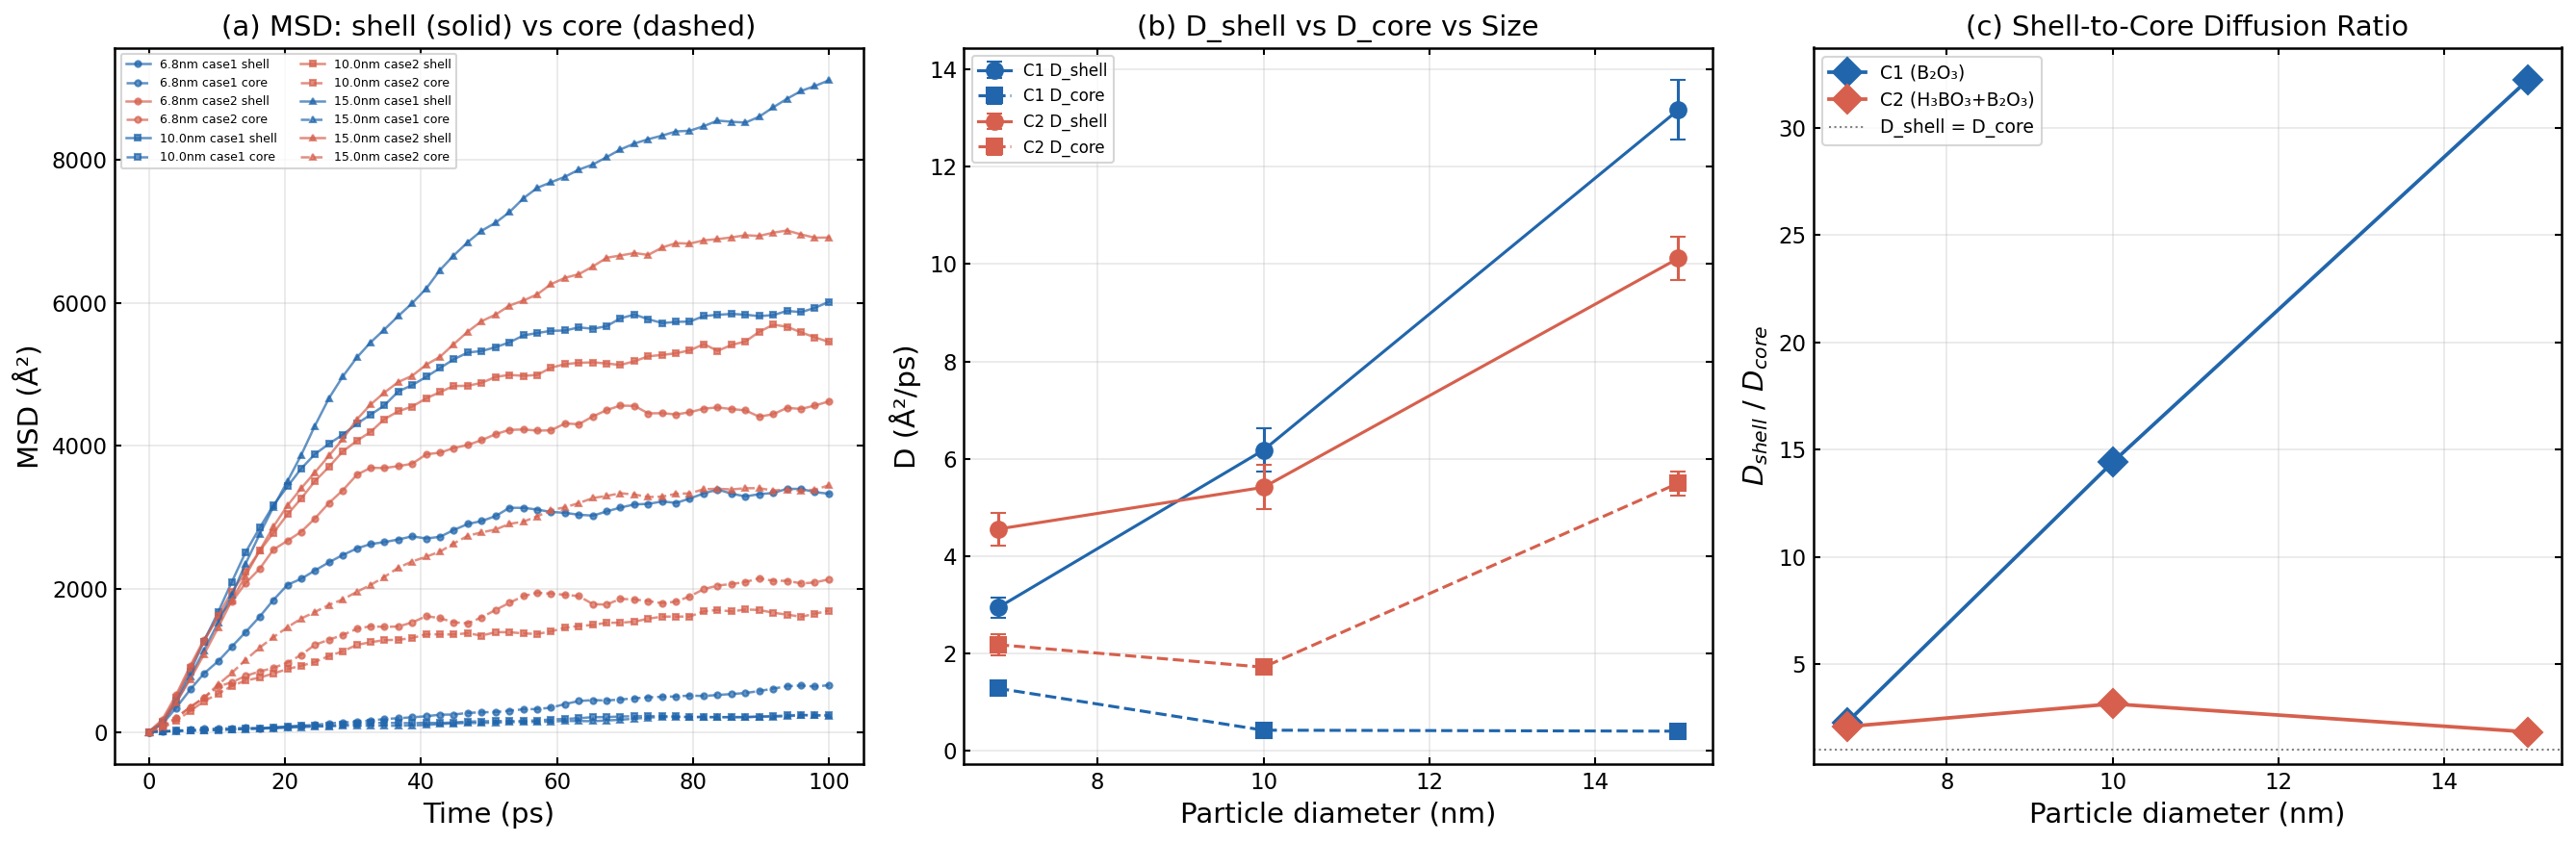


Physical interpretation:
If D_shell >> D_core:
  → O diffusion through B₂O₃ shell is fast, but slows in B core
  → Rate-limiting step is core penetration
  → Size dependence is mainly from core geometry

If D_shell << D_core:
  → Shell is the bottleneck (diffusion barrier)
  → Size dependence comes from curvature-dependent shell properties
  → H₃BO₃ effect is primarily shell modification

If D_shell ≈ D_core (ratio ≈ 1):
  → Both regions contribute equally
  → Need reaction-diffusion model rather than simple SCM

If D_shell/D_core ratio changes with size:
  → Curvature-dependent mechanism (smaller particle = more strained shell)

Figure saved: /mnt/dsk1/ljhlab/lammps/lammps_reaxff_B_nano/figures_extrapolation/D_shell_vs_D_core.png


In [28]:
# ─── Plot: D_shell vs D_core comparison ───

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ─── Panel 1: MSD curves (shell vs core) for each size ───
ax1 = axes[0]
for size_label in sizes:
    for case_label, color in [('case1', COLOR_CASE1), ('case2', COLOR_CASE2)]:
        key = (size_label, case_label)
        if key not in D_DECOMP:
            continue
        dd = D_DECOMP[key]
        marker = MARKERS[size_label]
        
        for region, ls in [('shell', '-'), ('core', '--')]:
            if region not in dd or len(dd[region].get('times', [])) == 0:
                continue
            t = dd[region]['times']
            m = dd[region]['msd']
            valid = ~np.isnan(m)
            if valid.sum() < 2:
                continue
            # Subsample for clarity
            step = max(1, len(t) // 30)
            ax1.plot(t[valid][::step], m[valid][::step], ls=ls, color=color,
                     marker=marker, markersize=3, lw=1.2, alpha=0.7,
                     label=f'{size_label} {case_label} {region}')

ax1.set_xlabel('Time (ps)')
ax1.set_ylabel('MSD (Å²)')
ax1.set_title('(a) MSD: shell (solid) vs core (dashed)')
ax1.legend(fontsize=6, ncol=2, loc='upper left')
ax1.grid(True, alpha=0.3)


# ─── Panel 2: D_shell and D_core vs particle size ───
ax2 = axes[1]

for case_label, color in [('case1', COLOR_CASE1), ('case2', COLOR_CASE2)]:
    d_vals = []
    Ds_vals, Ds_errs = [], []
    Dc_vals, Dc_errs = [], []
    
    for size_label in sizes:
        key = (size_label, case_label)
        if key not in D_DECOMP:
            continue
        dd = D_DECOMP[key]
        d_nm = SIZE_CONFIG[size_label]['d_nm']
        
        Ds = dd.get('shell', {}).get('D', np.nan)
        Dc = dd.get('core', {}).get('D', np.nan)
        Ds_e = dd.get('shell', {}).get('D_err', np.nan)
        Dc_e = dd.get('core', {}).get('D_err', np.nan)
        
        d_vals.append(d_nm)
        Ds_vals.append(Ds)
        Ds_errs.append(Ds_e)
        Dc_vals.append(Dc)
        Dc_errs.append(Dc_e)
    
    case_short = 'C1' if case_label == 'case1' else 'C2'
    
    # D_shell: circles, solid
    valid_s = [not np.isnan(v) for v in Ds_vals]
    d_s = [d for d, v in zip(d_vals, valid_s) if v]
    Ds_s = [v for v, ok in zip(Ds_vals, valid_s) if ok]
    Ds_e_s = [v for v, ok in zip(Ds_errs, valid_s) if ok]
    if d_s:
        ax2.errorbar(d_s, Ds_s, yerr=Ds_e_s, fmt='o-', color=color,
                     capsize=4, lw=1.5, markersize=8,
                     label=f'{case_short} D_shell')
    
    # D_core: squares, dashed
    valid_c = [not np.isnan(v) for v in Dc_vals]
    d_c = [d for d, v in zip(d_vals, valid_c) if v]
    Dc_c = [v for v, ok in zip(Dc_vals, valid_c) if ok]
    Dc_e_c = [v for v, ok in zip(Dc_errs, valid_c) if ok]
    if d_c:
        ax2.errorbar(d_c, Dc_c, yerr=Dc_e_c, fmt='s--', color=color,
                     capsize=4, lw=1.5, markersize=8,
                     label=f'{case_short} D_core')

ax2.set_xlabel('Particle diameter (nm)')
ax2.set_ylabel('D (Å²/ps)')
ax2.set_title('(b) D_shell vs D_core vs Size')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)


# ─── Panel 3: D_shell/D_core ratio vs size ───
ax3 = axes[2]

for case_label, color in [('case1', COLOR_CASE1), ('case2', COLOR_CASE2)]:
    d_vals = []
    ratios = []
    
    for size_label in sizes:
        key = (size_label, case_label)
        if key not in D_DECOMP:
            continue
        dd = D_DECOMP[key]
        Ds = dd.get('shell', {}).get('D', np.nan)
        Dc = dd.get('core', {}).get('D', np.nan)
        
        if not np.isnan(Ds) and not np.isnan(Dc) and Dc > 0:
            d_vals.append(SIZE_CONFIG[size_label]['d_nm'])
            ratios.append(Ds / Dc)
    
    case_short = 'C1 (B₂O₃)' if case_label == 'case1' else 'C2 (H₃BO₃+B₂O₃)'
    if d_vals:
        ax3.plot(d_vals, ratios, 'D-', color=color, markersize=10, lw=1.8,
                 label=case_short)

ax3.axhline(y=1.0, color='gray', ls=':', lw=1, label='D_shell = D_core')
ax3.set_xlabel('Particle diameter (nm)')
ax3.set_ylabel('$D_{shell}$ / $D_{core}$')
ax3.set_title('(c) Shell-to-Core Diffusion Ratio')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'D_shell_vs_D_core.png'), bbox_inches='tight', dpi=200)
plt.show()

# ─── Physical interpretation ───
print('\n' + '=' * 70)
print('Physical interpretation:')
print('=' * 70)
print('If D_shell >> D_core:')
print('  → O diffusion through B₂O₃ shell is fast, but slows in B core')
print('  → Rate-limiting step is core penetration')
print('  → Size dependence is mainly from core geometry')
print()
print('If D_shell << D_core:')
print('  → Shell is the bottleneck (diffusion barrier)')
print('  → Size dependence comes from curvature-dependent shell properties')
print('  → H₃BO₃ effect is primarily shell modification')
print()
print('If D_shell ≈ D_core (ratio ≈ 1):')
print('  → Both regions contribute equally')
print('  → Need reaction-diffusion model rather than simple SCM')
print()
print('If D_shell/D_core ratio changes with size:')
print('  → Curvature-dependent mechanism (smaller particle = more strained shell)')
print(f'\nFigure saved: {os.path.join(FIG_DIR, "D_shell_vs_D_core.png")}')